# Appendix: full working notebook

This is the complete working record behind the case study (`wombloom_case_study.ipynb`). It keeps every intermediate table, every check and every judgment call in the order they were made, including drafts that were later revised (for example the theme codebook in section 14, which section 15 changes).

The scripts in `src/` do the work; this notebook reads their outputs. Re-running it needs the local review database, which is not published (review text stays private), so the saved outputs are what you see on GitHub.

| Sections | Step | Script |
|---|---|---|
| 1 to 5 | App discovery | `src/discover_apps.py` |
| 6 to 7 | App Store reviews | `src/fetch_appstore_reviews.py` |
| 8 | Clean and load into SQLite | `src/clean_and_load.py` |
| 9 to 10 | Data quality report | this notebook |
| 11 to 17 | Review analysis, themes, feature gap matrix, conclusions | `src/themes.py` |
| 18 to 19 | Prioritization and plan vs reality | `src/prioritize.py`, `src/build_aggregates.py` |
| 20 to 23 | Working with AI, the build story, measurement plan, dashboard | |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# VS Code usually runs notebooks from the project root. If this one runs from notebooks/, step up one folder.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CLEAN = ROOT / 'data' / 'clean'
LOG = ROOT / 'docs' / 'app_selection_log.md'

all_apps = pd.read_csv(CLEAN / 'app_candidates_all.csv')
filtered = pd.read_csv(CLEAN / 'app_candidates_filtered.csv')
all_apps['rating_count'] = all_apps[['rating_count_us', 'rating_count_ca']].max(axis=1).fillna(0).astype(int)

print(f'{len(all_apps):,} unique apps found, {len(filtered)} after filters')

1,464 unique apps found, 92 after filters


## 1. Filter funnel

The funnel is written to `docs/app_selection_log.md` by the script. This cell reads that table so the numbers match the log exactly.

In [2]:
def read_log_table(heading):
    """Return the first markdown table under a heading in the selection log."""
    section = LOG.read_text(encoding='utf-8').split(heading, 1)[1].split('\n## ', 1)[0]
    rows = [[cell.strip() for cell in line.strip().strip('|').split('|')]
            for line in section.splitlines() if line.startswith('|')]
    return pd.DataFrame(rows[2:], columns=rows[0])  # rows[1] is the |---| separator


funnel = read_log_table('## 2. Filter funnel')
funnel['Removed'] = pd.to_numeric(funnel['Removed'], errors='coerce')
funnel['Remaining'] = funnel['Remaining'].astype(int)
funnel

,Step,Removed,Remaining
0,All unique apps found,NaN,1464
1,Relevance: pregnancy or baby terms in name/des...,170.0,1294
2,"Category in ['Education', 'Health & Fitness', ...",119.0,1175
3,Out of scope: cycle/fertility tracker without ...,39.0,1136
4,"At least 1,000 ratings",1027.0,109
5,Updated within 365 days,13.0,96
6,Duplicate / regional clone (same normalized name),4.0,92


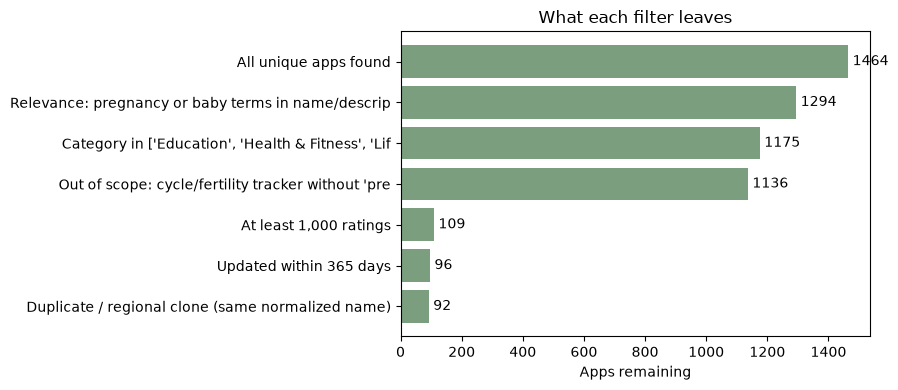

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(funnel['Step'].str.slice(0, 50), funnel['Remaining'], color='#7a9e7e')
ax.invert_yaxis()
ax.set_xlabel('Apps remaining')
ax.set_title('What each filter leaves')
for y, value in enumerate(funnel['Remaining']):
    ax.text(value + 15, y, str(value), va='center')
plt.tight_layout()
plt.show()

## 2. Candidate segments

The segments come from keyword rules in the script, so each placement can be checked against its name and description.
"Pregnancy other" holds pregnancy apps that fit no segment. It is left out of the tables below.

In [4]:
filtered['segment'].value_counts()

segment
Adjacent             43
Pregnancy other      35
Category leader      10
Direct competitor     4
Name: count, dtype: int64

In [5]:
columns = ['name', 'developer', 'category', 'rating_count', 'avg_rating_us', 'avg_rating_ca']
for segment in ['Direct competitor', 'Category leader', 'Adjacent']:
    print(f'\n{segment}')
    display(filtered.query('segment == @segment')[columns].sort_values('rating_count', ascending=False))


Direct competitor


,name,developer,category,rating_count,avg_rating_us,avg_rating_ca
26,Qeepsake: Family Photo Album,Tinybeans USA Ltd.,Lifestyle,14630.0,4.88605,4.81062
44,Cubtale: Pregnancy & Baby,Cubtale,Medical,7403.0,4.84802,4.82326
56,BabyPage: Baby Book & Journal,BabyPage Inc,Lifestyle,4097.0,4.82109,4.68207
64,Dad Pregnancy Guide: Daddy Up,"Sycamore Spur, LLC",Health & Fitness,2952.0,4.85975,4.86100



Category leader


,name,developer,category,rating_count,avg_rating_us,avg_rating_ca
0,Pregnancy Tracker App - WTE,"Everyday Health, Inc.",Medical,380433.0,4.87040,4.78332
1,BabyCenter Pregnancy Tracker,"Everyday Health, Inc.",Medical,298404.0,4.89192,4.85863
6,Ovia Cycle & Pregnancy Tracker,"Ovuline, Inc.",Medical,90752.0,4.82531,4.76030
7,Pregnancy + | Tracker App,Philips Digital UK Limited,Medical,76780.0,4.84809,4.81449
10,IVY Period & Pregnancy Tracker,"String Health, Inc.",Health & Fitness,67896.0,4.66228,4.52151
11,The Bump: Pregnancy & Baby App,The Knot Inc.,Health & Fitness,40161.0,4.84856,4.82963
14,Nurture Pregnancy Week by Week,Glow,Medical,30266.0,4.79905,4.69778
18,WeMoms - Pregnancy & Baby App,Globalia,Medical,27313.0,4.79175,4.70924
20,Nara Baby & Pregnancy Tracker,Nara,Medical,24455.0,4.85193,4.80597
22,Pregnancy App.,Amila Tech Limited,Medical,23222.0,4.88842,4.87927



Adjacent


,name,developer,category,rating_count,avg_rating_us,avg_rating_ca
2,Baby Tracker - Newborn Log,Nighp Software LLC,Medical,227368.0,4.80082,4.76307
3,Precious - Baby Photo Art,Curious Creators Co.,Lifestyle,138727.0,4.75139,4.68640
4,The Wonder Weeks - Baby leaps,Domus Technica,Health & Fitness,122351.0,4.84462,4.75711
8,Huckleberry: Baby Tracker,Huckleberry Labs Inc.,Medical,75363.0,4.92279,4.89806
12,Nanit,Udisense inc.,Lifestyle,38245.0,4.68001,4.55506
13,Baby Tracker & Newborn Log,Med ART Studios,Medical,31537.0,4.77737,4.71133
16,BackThen - Baby Book & Albums,Back Then Digital Ltd,Lifestyle,29045.0,4.84603,4.76735
17,My Diary - Journal with Lock,"BetterApp Tech Co., Limited",Lifestyle,28315.0,4.74081,4.65983
19,"Baby Feed Timer, breastfeeding",Fehners Software LLP,Lifestyle,24567.0,4.85285,4.81967
21,Glow Baby Tracker & Growth App,Glow,Medical,23465.0,4.67321,4.63894


## 3. Shortlist

The shortlist is hand-picked from the segment tables and recorded in section 6 of the log. Update both if the list changes.
280days is below the 1,000-rating threshold. It is included on purpose as the closest match to Wombloom's concept.

In [6]:
SHORTLIST = {
    'Direct': [1541460870, 1332312787, 995864179],
    'Category leader': [289560144, 505864483, 568940747, 882398397],
    'Adjacent': [779656557, 1169136078, 1077177456],
}
group_of = {app_id: group for group, ids in SHORTLIST.items() for app_id in ids}

shortlist = all_apps[all_apps['app_id'].isin(group_of)].copy()
shortlist['group'] = shortlist['app_id'].map(group_of)
shortlist['last_updated'] = pd.to_datetime(shortlist['last_updated'], utc=True).dt.date
shortlist = shortlist.sort_values(['group', 'rating_count'], ascending=[True, False])
shortlist[['group', 'name', 'developer', 'rating_count', 'avg_rating_us', 'avg_rating_ca', 'last_updated', 'app_id']]

,group,name,developer,rating_count,avg_rating_us,avg_rating_ca,last_updated,app_id
587,Adjacent,Baby Tracker - Newborn Log,Nighp Software LLC,227368,4.80082,4.76307,2026-10-20,779656557
62,Adjacent,Huckleberry: Baby Tracker,Huckleberry Labs Inc.,75363,4.92279,4.89806,2026-10-22,1169136078
591,Adjacent,Glow Baby Tracker & Growth App,Glow,23465,4.67321,4.63894,2025-11-05,1077177456
1,Category leader,Pregnancy Tracker App - WTE,"Everyday Health, Inc.",380433,4.87040,4.78332,2026-10-19,289560144
0,Category leader,Pregnancy + | Tracker App,Philips Digital UK Limited,76780,4.84809,4.81449,2026-08-10,505864483
5,Category leader,The Bump: Pregnancy & Baby App,The Knot Inc.,40161,4.84856,4.82963,2026-10-21,568940747
29,Category leader,Nurture Pregnancy Week by Week,Glow,30266,4.79905,4.69778,2026-05-04,882398397
189,Direct,Qeepsake: Family Photo Album,Tinybeans USA Ltd.,14630,4.88605,4.81062,2026-09-08,1332312787
73,Direct,Cubtale: Pregnancy & Baby,Cubtale,7403,4.84802,4.82326,2026-10-14,1541460870
94,Direct,280days : Pregnancy Diary App,amane factory inc.,482,4.75311,4.69892,2026-08-12,995864179


## 4. Which search terms found the apps

Each app records every query that returned it (`found_by`). Counting those gives each term's contribution, and a count of apps found by only one query shows how much the result depends on a single term.

In [7]:
keyword_hits = (all_apps['found_by'].dropna()
                .str.split('; ').explode()
                .str.replace(r'^(us|ca):', '', regex=True)
                .value_counts())
print(f"Apps found by only one query: {(all_apps['found_by'].str.count(';') == 0).sum()}")
keyword_hits.to_frame('hits (US + CA)')

Apps found by only one query: 610


,hits (US + CA)
found_by,
newborn tracker,384
baby feeding sleep tracker,383
postpartum,380
baby tracker,369
pregnancy app,367
pregnancy journal,364
prenatal,364
pregnancy tracker,361
pregnancy week by week,350


## 5. Pregnancy journal apps in the search results

The closest apps to a pregnancy journal have very few ratings. This is why the Direct group relaxes the 1,000-rating rule.

In [8]:
journal = all_apps[
    all_apps['name'].str.contains('journal|diary', case=False, na=False)
    & all_apps['name'].str.contains('pregnan|bump|baby', case=False, na=False)
]
journal.sort_values('rating_count', ascending=False)[['name', 'developer', 'rating_count']]

,name,developer,rating_count
182,BabyPage: Baby Book & Journal,BabyPage Inc,4097
194,Baby Photo Editor: Pic Journal,"PlusMinusOne, Inc.",2273
94,280days : Pregnancy Diary App,amane factory inc.,482
315,Pregnancy Calculator & Diary,Reticode,356
689,Baby's Journal,Yinghua Wu,338
127,Mommy - Baby Tracker & Diary,llapps,44
200,Baby Diaries - Book Journal,Journal Lab B.V.,15
262,Sproutbook: Baby Journal,Palex & Co. LLC,13
697,Baby Tracker - Newborn Diary,llapps,8
1370,Baby sleep diary - tracker,Aksana Meshcharakova,4


## 6. App Store reviews: what was collected

Checkpoint 2 of the plan. The feed returns at most 500 of the most recent reviews per app and country (10 pages of 50), so the sample is skewed toward recent experience. The tables and charts below show how much was collected and how far back it reaches.

In [9]:
reviews = pd.read_csv(CLEAN / 'appstore_reviews.csv', parse_dates=['review_date'])
coverage = pd.read_csv(CLEAN / 'appstore_coverage.csv', parse_dates=['first_date', 'last_date'])

SEGMENT_ORDER = ['Direct', 'Category leader', 'Adjacent']
coverage['segment'] = pd.Categorical(coverage['segment'], SEGMENT_ORDER, ordered=True)
coverage = coverage.sort_values(['segment', 'app_name', 'country']).reset_index(drop=True)
APP_ORDER = coverage['app_name'].unique()  # shortlist order, grouped by segment
COUNTRY_COLORS = {'us': '#4c78a8', 'ca': '#f58518'}

print(f"{len(reviews):,} reviews, {reviews['app_id'].nunique()} apps, countries: {sorted(reviews['country'].unique())}")
print(f"Same review id appearing in both countries: {reviews.duplicated(['app_id', 'review_id']).sum()}")
coverage.assign(avg_rating=coverage['avg_rating'].round(2))[['segment', 'app_name', 'country', 'reviews', 'first_date', 'last_date', 'days_covered', 'avg_rating']]

7,955 reviews, 10 apps, countries: ['ca', 'us']
Same review id appearing in both countries: 0


,segment,app_name,country,reviews,first_date,last_date,days_covered,avg_rating
0,Direct,280days: Pregnancy Diary App,ca,14,2017-11-17 01:00:09+00:00,2025-01-31 11:50:37+00:00,2632,4.29
1,Direct,280days: Pregnancy Diary App,us,105,2016-06-14 03:27:34+00:00,2026-06-03 14:34:22+00:00,3641,4.30
2,Direct,Cubtale: Pregnancy & Baby,ca,10,2021-08-23 20:00:40+00:00,2026-05-14 03:01:50+00:00,1724,4.30
3,Direct,Cubtale: Pregnancy & Baby,us,321,2021-08-23 03:25:15+00:00,2026-10-19 22:23:55+00:00,1883,4.08
4,Direct,Qeepsake: Family Photo Album,ca,86,2018-04-12 21:57:06+00:00,2026-05-25 14:34:55+00:00,2964,4.02
5,Direct,Qeepsake: Family Photo Album,us,500,2019-12-08 02:25:42+00:00,2026-10-05 15:32:03+00:00,2493,4.19
6,Category leader,Nurture Pregnancy Week by Week,ca,419,2014-07-18 18:33:21+00:00,2026-05-31 13:55:21+00:00,4334,4.40
7,Category leader,Nurture Pregnancy Week by Week,us,500,2021-07-16 12:51:53+00:00,2026-10-08 11:26:49+00:00,1909,3.87
8,Category leader,Pregnancy + | Tracker App,ca,500,2016-03-17 19:20:07+00:00,2026-10-16 05:55:33+00:00,3864,4.08
9,Category leader,Pregnancy + | Tracker App,us,500,2022-03-13 16:21:43+00:00,2026-10-13 17:03:49+00:00,1675,3.99


### Volume: how many reviews per app

The dashed line is the feed's 500-review limit. Bars that stop short of it mean the app has fewer reviews than the limit in that country.

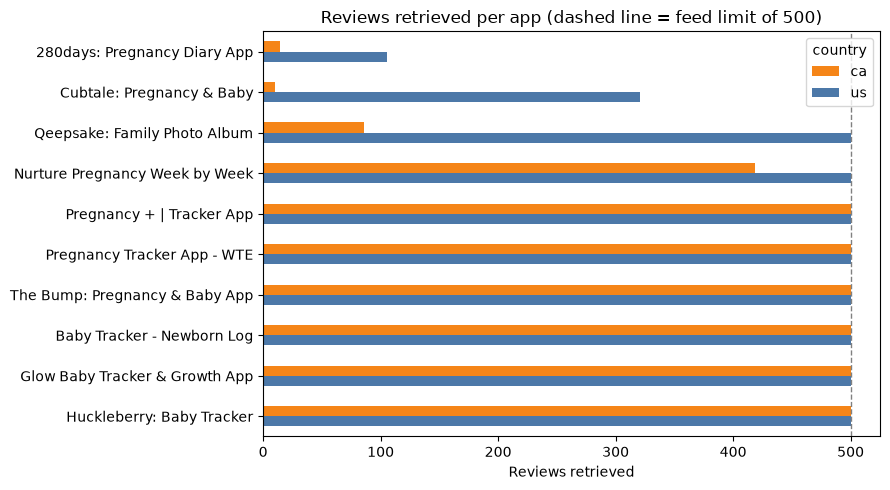

In [10]:
counts = coverage.pivot(index='app_name', columns='country', values='reviews').reindex(APP_ORDER)
ax = counts.plot.barh(figsize=(9, 5), color=COUNTRY_COLORS)
ax.invert_yaxis()
ax.axvline(500, color='grey', linestyle='--', linewidth=1)
ax.set_xlabel('Reviews retrieved')
ax.set_ylabel('')
ax.set_title('Reviews retrieved per app (dashed line = feed limit of 500)')
plt.tight_layout()
plt.show()

### Date coverage: how far back the reviews reach

This is the main limitation of the feed. A short bar means the 500 reviews cover only a few weeks, so the sample reflects that period and not the app's full history.

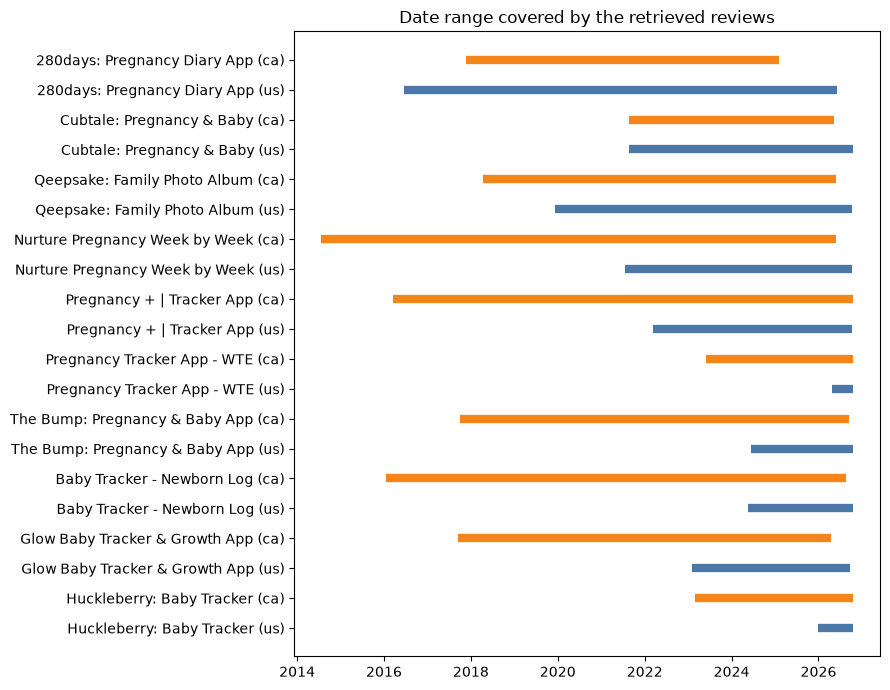

In [11]:
labels = (coverage['app_name'] + ' (' + coverage['country'] + ')').tolist()
bar_colors = coverage['country'].map(COUNTRY_COLORS).tolist()

fig, ax = plt.subplots(figsize=(9, 7))
ax.hlines(range(len(coverage)), coverage['first_date'], coverage['last_date'], colors=bar_colors, linewidth=6)
ax.set_yticks(range(len(coverage)), labels)
ax.invert_yaxis()
ax.set_title('Date range covered by the retrieved reviews')
plt.tight_layout()
plt.show()

### Star ratings: what the sample looks like

Each bar shows the share of retrieved reviews at each star rating. The right-hand segments are the happy reviewers. The left-hand ones are where feature gaps and complaints will be found.

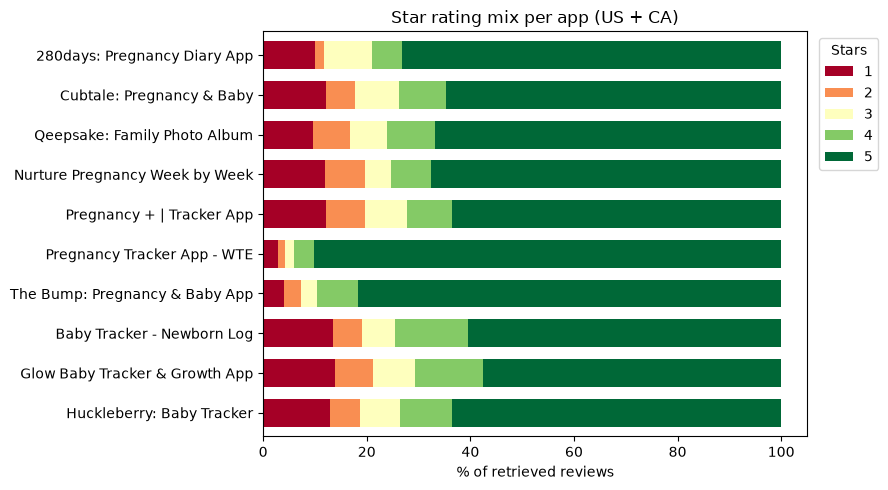

In [12]:
mix = (pd.crosstab(reviews['app_name'], reviews['rating'], normalize='index') * 100).reindex(APP_ORDER)
ax = mix.plot.barh(stacked=True, figsize=(9, 5), colormap='RdYlGn', width=0.7)
ax.invert_yaxis()
ax.set_xlabel('% of retrieved reviews')
ax.set_ylabel('')
ax.set_title('Star rating mix per app (US + CA)')
ax.legend(title='Stars', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

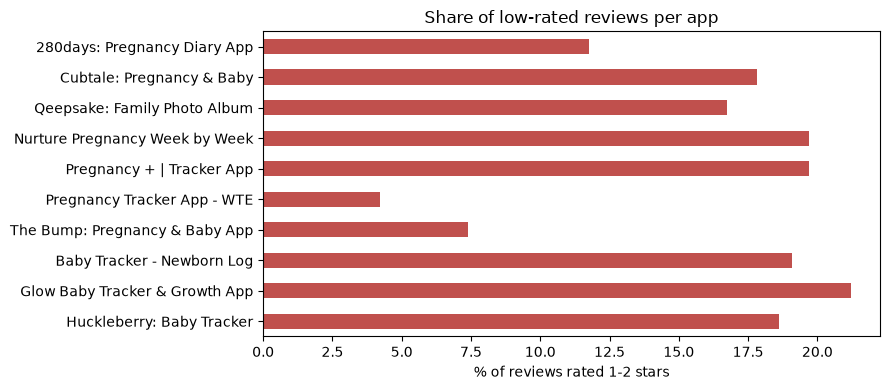

In [13]:
low = (reviews.assign(low=reviews['rating'] <= 2).groupby('app_name')['low'].mean() * 100).reindex(APP_ORDER)
ax = low.plot.barh(figsize=(9, 4), color='#c0504d')
ax.invert_yaxis()
ax.set_xlabel('% of reviews rated 1-2 stars')
ax.set_ylabel('')
ax.set_title('Share of low-rated reviews per app')
plt.tight_layout()
plt.show()

### Review length: is there enough text to analyze?

Very short reviews ("great app", "love it") carry little signal for theme analysis. This table shows how much usable text each app has.

In [14]:
reviews['words'] = reviews['text'].fillna('').str.split().str.len()
length = reviews.groupby('app_name').agg(
    reviews=('words', 'size'),
    median_words=('words', 'median'),
    pct_under_5_words=('words', lambda s: (s < 5).mean() * 100),
    pct_over_30_words=('words', lambda s: (s >= 30).mean() * 100),
).round(1).reindex(APP_ORDER)
length

,reviews,median_words,pct_under_5_words,pct_over_30_words
app_name,,,,
280days: Pregnancy Diary App,119,18.0,11.8,30.3
Cubtale: Pregnancy & Baby,331,41.0,2.1,64.0
Qeepsake: Family Photo Album,586,51.0,1.9,71.8
Nurture Pregnancy Week by Week,919,20.0,16.8,37.6
Pregnancy + | Tracker App,1000,25.0,8.3,44.1
Pregnancy Tracker App - WTE,1000,17.0,15.1,26.0
The Bump: Pregnancy & Baby App,1000,25.0,7.3,42.3
Baby Tracker - Newborn Log,1000,37.0,4.6,60.9
Glow Baby Tracker & Growth App,1000,34.0,6.1,55.5


## 7. Findings so far (checkpoint 2)

**Volume**
- 7,955 reviews across 10 apps (US 4,426, CA 3,529). No review ID appears in both countries.
- Six of the ten apps hit the feed limit of 500 in both countries. The other four have fewer: Cubtale (321 US, 10 CA), Qeepsake (500 US, 86 CA), 280days (105 US, 14 CA) and Nurture (500 US, 419 CA).

**Time windows differ a lot between apps**
- 500 reviews cover very different periods: Pregnancy Tracker App - WTE (US) spans only about 6 months (183 days) and Huckleberry (US) about 10 months, while Nurture (CA) spans almost 12 years. Compare apps with care, because a short window reflects only recent app versions and a long one mixes old and new.
- This is the recency limitation of the feed, and it will go in the data quality report.

**Ratings**
- WTE has 4.2% low-rated (1-2 star) reviews and The Bump has 7.4%. The other apps sit between 12% and 21%. WTE's recent window is short and its reviews are overwhelmingly 5 stars, which may reflect in-app rating prompts. Treat WTE and The Bump as less informative for complaint analysis.
- Glow Baby (21%), Nurture and Pregnancy+ (20% each) and the other baby trackers (19%) have the most low-rated reviews, so they are the richest source of pain points.

**Text for analysis**
- The Direct competitors write the longest reviews (median 18 to 51 words, and Cubtale and Qeepsake have 64% and 72% of reviews at 30+ words), but there are few of them: 119 for 280days, 331 for Cubtale, 586 for Qeepsake.
- WTE has the most short reviews (15% under 5 words, median 17 words), so much of its sample carries little signal.

**Decisions needed**
- The Canadian samples for 280days (14) and Cubtale (10) are too small to use on their own. Combining US and CA is the practical option.
- Step 4 (Google Play) can add reviews for the Direct group, but those apps may be smaller on Android too.

**Fixed during collection:** the feed returned an empty page for WTE (US) on the first run, which looked like the end of the feed. The fetcher now re-checks an empty page three times before treating it as the end.

## 8. Cleaning and loading (Step 5)

`src/clean_and_load.py` combines the extracted reviews into one schema, removes exact duplicates, detects the language of each review and flags very short ones (under 5 words). Nothing else is deleted, and the original review text is kept untouched. The results are loaded into SQLite, and the cells below read the data back from the database.

In [15]:
import sqlite3

DB = ROOT / 'data' / 'wombloom.db'
DOCS = ROOT / 'docs'
FIGS = DOCS / 'figures' / 'appendix'
FIGS.mkdir(parents=True, exist_ok=True)
con = sqlite3.connect(DB)

for table in ['apps', 'reviews']:
    n = con.execute(f'select count(*) from {table}').fetchone()[0]
    print(f'{table}: {n:,} rows')
pd.read_sql('pragma table_info(reviews)', con)[['name', 'type']].T

apps: 10 rows
reviews: 7,955 rows


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
name,platform,app_id,app_name,segment,country,review_id,rating,title,text,review_date,app_version,language,is_english,word_count,is_short,is_empty,is_duplicate
type,TEXT,INTEGER,TEXT,TEXT,TEXT,INTEGER,INTEGER,TEXT,TEXT,TEXT,TEXT,TEXT,INTEGER,INTEGER,INTEGER,INTEGER,INTEGER


In [16]:
pd.read_sql('select app_id, app_name, segment, developer, category, price, store_rating_count from apps order by segment, store_rating_count desc', con)

,app_id,app_name,segment,developer,category,price,store_rating_count
0,779656557,Baby Tracker - Newborn Log,Adjacent,Nighp Software LLC,Medical,0.0,227368.0
1,1169136078,Huckleberry: Baby Tracker,Adjacent,Huckleberry Labs Inc.,Medical,0.0,75363.0
2,1077177456,Glow Baby Tracker & Growth App,Adjacent,Glow,Medical,0.0,23465.0
3,289560144,Pregnancy Tracker App - WTE,Category leader,"Everyday Health, Inc.",Medical,0.0,380433.0
4,505864483,Pregnancy + | Tracker App,Category leader,Philips Digital UK Limited,Medical,0.0,76780.0
5,568940747,The Bump: Pregnancy & Baby App,Category leader,The Knot Inc.,Health & Fitness,0.0,40161.0
6,882398397,Nurture Pregnancy Week by Week,Category leader,Glow,Medical,0.0,30266.0
7,1332312787,Qeepsake: Family Photo Album,Direct,Tinybeans USA Ltd.,Lifestyle,0.0,14630.0
8,1541460870,Cubtale: Pregnancy & Baby,Direct,Cubtale,Medical,0.0,7403.0
9,995864179,280days: Pregnancy Diary App,Direct,amane factory inc.,Medical,0.0,482.0


### What the cleaning step did

The cleaning counts: rows read, exact duplicates removed, rows loaded, and how many reviews carry each flag.
`language_undetermined` reviews are text too short for reliable detection (under 20 characters), so they are not necessarily non-English.

In [17]:
rows_in = len(pd.read_csv(CLEAN / 'appstore_reviews.csv'))
rows_out = con.execute('select count(*) from reviews').fetchone()[0]
print(f'Rows read: {rows_in:,}   exact duplicates removed: {rows_in - rows_out}   rows loaded: {rows_out:,}')

pd.read_sql("""
    select sum(is_english = 0) as non_english_or_undetermined,
           sum(language = 'und') as language_undetermined,
           sum(is_short) as short_under_5_words,
           sum(is_empty) as empty_text
    from reviews
""", con)

Rows read: 7,955   exact duplicates removed: 0   rows loaded: 7,955


,non_english_or_undetermined,language_undetermined,short_under_5_words,empty_text
0,850,513,627,0


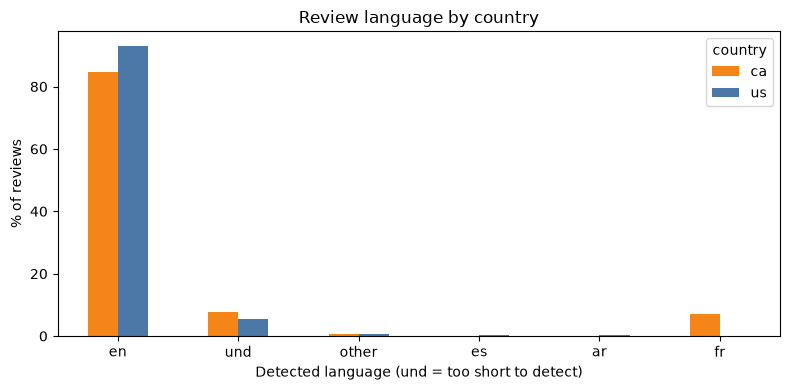

In [18]:
lang = pd.read_sql('select country, language, count(*) as n from reviews group by country, language', con)
top = lang.groupby('language')['n'].sum().nlargest(5).index  # the 5 most common languages overall
lang['language'] = lang['language'].where(lang['language'].isin(top), 'other')
share = lang.groupby(['country', 'language'])['n'].sum().unstack(fill_value=0)
share = share.div(share.sum(axis=1), axis=0) * 100

ax = share.T.sort_values('us', ascending=False).plot.bar(figsize=(8, 4), color=COUNTRY_COLORS)
ax.set_ylabel('% of reviews')
ax.set_xlabel('Detected language (und = too short to detect)')
ax.set_title('Review language by country')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGS / 'language_by_country.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Data quality report (Step 6)

This section is the quality report: volume, time coverage, rating balance, how much of the text is usable, and the limitations. The charts are also saved to `docs/`, and `docs/data_quality_report.md` summarizes the results. Date coverage per app was charted in section 6.

### 9.1 Volume per app, country and platform

All reviews are from the iOS App Store.

In [19]:
volume = pd.read_sql('select segment, app_name, country, count(*) as n from reviews group by 1, 2, 3', con)
table = volume.pivot_table(index=['segment', 'app_name'], columns='country', values='n', aggfunc='sum', fill_value=0)
table['total'] = table.sum(axis=1)
table.loc[('All', 'All apps'), :] = table.sum()
table.astype(int)

country                                           ca    us  total
segment         app_name                                         
Adjacent        Baby Tracker - Newborn Log       500   500   1000
                Glow Baby Tracker & Growth App   500   500   1000
                Huckleberry: Baby Tracker        500   500   1000
Category leader Nurture Pregnancy Week by Week   419   500    919
                Pregnancy + | Tracker App        500   500   1000
                Pregnancy Tracker App - WTE      500   500   1000
                The Bump: Pregnancy & Baby App   500   500   1000
Direct          280days: Pregnancy Diary App      14   105    119
                Cubtale: Pregnancy & Baby         10   321    331
                Qeepsake: Family Photo Album      86   500    586
All             All apps                        3529  4426   7955

### 9.2 When the reviews were written

The feed returns the most recent reviews, so the data leans heavily toward the last few years. This chart shows how many reviews come from each year, by segment.

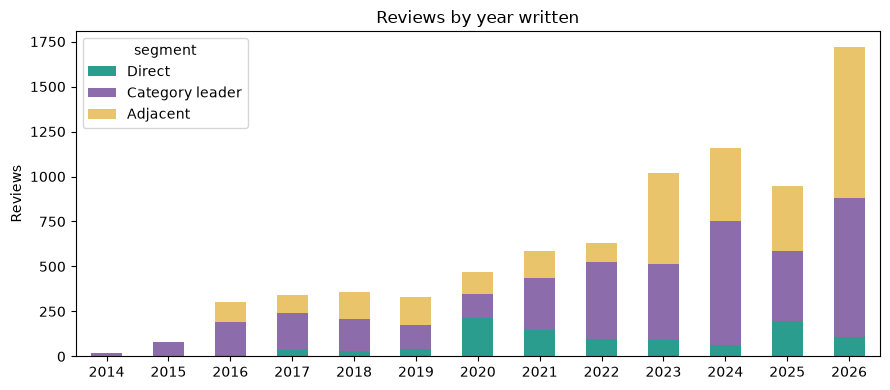

Share of all reviews written in the last 12 months of the data: 24.2%


In [20]:
SEGMENT_COLORS = {'Direct': '#2a9d8f', 'Category leader': '#8d6cab', 'Adjacent': '#e9c46a'}

by_year = pd.read_sql("select substr(review_date, 1, 4) as year, segment, count(*) as n from reviews group by 1, 2", con)
by_year = by_year.pivot(index='year', columns='segment', values='n').fillna(0)[list(SEGMENT_COLORS)]

ax = by_year.plot.bar(stacked=True, figsize=(9, 4), color=SEGMENT_COLORS)
ax.set_ylabel('Reviews')
ax.set_xlabel('')
ax.set_title('Reviews by year written')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGS / 'reviews_by_year.png', dpi=150, bbox_inches='tight')
plt.show()

cutoff = reviews['review_date'].max() - pd.Timedelta(days=365)
print(f"Share of all reviews written in the last 12 months of the data: {(reviews['review_date'] >= cutoff).mean():.1%}")

### 9.3 Rating distribution per app

Percent of each app's reviews at each star rating. The chart in section 6 shows the same data as stacked bars.

In [21]:
rating_pct = (pd.crosstab(reviews['app_name'], reviews['rating'], normalize='index') * 100).round(1).reindex(APP_ORDER)
rating_pct.columns = [f'{c} star' for c in rating_pct.columns]
rating_pct

,1 star,2 star,3 star,4 star,5 star
app_name,,,,,
280days: Pregnancy Diary App,10.1,1.7,9.2,5.9,73.1
Cubtale: Pregnancy & Baby,12.1,5.7,8.5,9.1,64.7
Qeepsake: Family Photo Album,9.6,7.2,7.2,9.2,66.9
Nurture Pregnancy Week by Week,12.0,7.7,5.0,7.6,67.7
Pregnancy + | Tracker App,12.2,7.5,8.1,8.7,63.5
Pregnancy Tracker App - WTE,2.9,1.3,1.8,3.9,90.1
The Bump: Pregnancy & Baby App,4.0,3.4,2.9,8.1,81.6
Baby Tracker - Newborn Log,13.4,5.7,6.3,14.1,60.5
Glow Baby Tracker & Growth App,13.9,7.3,8.2,13.1,57.5


### 9.4 How much of the text is usable

For theme and sentiment analysis, a review needs to be in English and have at least 5 words. Reviews that fail are kept in the database but flagged, so the analysis can exclude them.

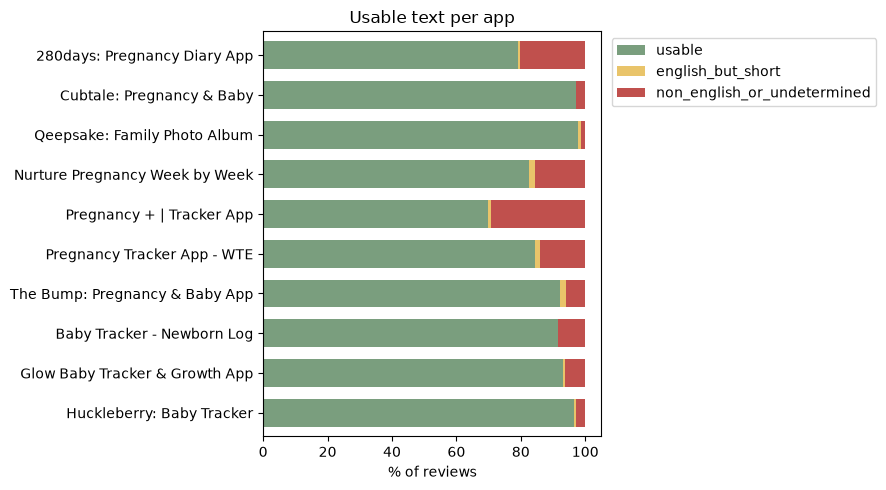

7,024 of 7,955 reviews are English with at least 5 words


,segment,reviews,usable
0,Adjacent,3000,2814
1,Category leader,3919,3221
2,Direct,1036,989


In [22]:
usable = pd.read_sql("""
    select app_name,
           sum(is_english = 1 and is_short = 0) as usable,
           sum(is_english = 1 and is_short = 1) as english_but_short,
           sum(is_english = 0) as non_english_or_undetermined
    from reviews group by app_name
""", con).set_index('app_name').reindex(APP_ORDER)

colors = {'usable': '#7a9e7e', 'english_but_short': '#e9c46a', 'non_english_or_undetermined': '#c0504d'}
ax = (usable.div(usable.sum(axis=1), axis=0) * 100).plot.barh(stacked=True, figsize=(9, 5), color=colors, width=0.7)
ax.invert_yaxis()
ax.set_xlabel('% of reviews')
ax.set_ylabel('')
ax.set_title('Usable text per app')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig(FIGS / 'usable_reviews_by_app.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"{usable['usable'].sum():,} of {usable.sum().sum():,} reviews are English with at least 5 words")
by_segment = pd.read_sql('select segment, count(*) as reviews, sum(is_english = 1 and is_short = 0) as usable from reviews group by segment', con)
by_segment

## 10. Summary and limitations

**What the data looks like**
- 7,955 reviews from 10 iOS apps (US 4,426, CA 3,529), spanning July 2014 to October 2026. No duplicates and no empty reviews were found.
- 89.3% of reviews are English. 850 are non-English or undetermined, including 513 that are too short to detect.
- 7,024 reviews (88.3%) are English with at least 5 words and are usable for text analysis: 2,814 Adjacent, 3,221 Category leader and 989 Direct.
- Direct competitors have the highest text quality but the smallest samples. Usable reviews: Qeepsake 573 (98%), Cubtale 322 (97%), 280days 94 (79%).
- Pregnancy+ has the lowest usable share (70%), because 197 of its 1,000 reviews are French (mostly Canadian).
- Canada has more non-English reviews than the US (15.4% against 6.9%).

**Limitations**
1. **Recent reviews only.** The feed returns at most 500 reviews per app and country, newest first. The time window varies from about 6 months (WTE, US) to almost 12 years (Nurture, CA). 24.2% of all reviews were written in the last 12 months of the data, and 2026 (a partial year) has more reviews than any earlier year.
2. **Self-selection.** Only some users write reviews, and they skew toward strong opinions. Ratings are heavily 5-star (58% to 90% by app). Apps that prompt users to rate, such as WTE (90% five-star), will look better than they are.
3. **iOS only.** Android users are not represented. Google Play was skipped on purpose.
4. **US and Canada only.** Results may not apply to other markets.
5. **Small Direct sample.** The closest apps to a pregnancy journal have few reviews, and the Canadian samples for 280days (14) and Cubtale (10) are too small to use alone. Treat Direct findings as directional.
6. **Language detection is approximate.** It is unreliable on very short text, so those reviews are marked undetermined and excluded from the usable count.
7. **Selection method.** Apps were found through keyword searches (top 200 results per query), so apps that rank poorly for those terms may be missing.

In [23]:
con.close()

## 11. Review analysis: the frame

Part 1 (sections 1 to 10) collected and checked the data. Part 2 turns the reviews into product insight for Wombloom.

**Questions**
1. What do users love in pregnancy and baby apps?
2. What frustrates them?
3. Where do the Direct competitors (journal-style apps) leave gaps?
4. What should Wombloom prioritize?

**Sample:** the 7,024 usable reviews (English, at least 5 words), US and CA pooled. The apps have very different time windows (section 6), so every comparison is run twice: on all reviews, and on the last 24 months only. Rates are reported per app so the large apps do not dominate the totals.

In [24]:
import numpy as np

con = sqlite3.connect(DB)
sample = pd.read_sql('select * from reviews where is_english = 1 and is_short = 0', con)
con.close()

sample['review_date'] = pd.to_datetime(sample['review_date'], utc=True)
WINDOW_CUTOFF = sample['review_date'].max() - pd.DateOffset(months=24)
sample['recent'] = sample['review_date'] >= WINDOW_CUTOFF
sample['text_full'] = (sample['title'].fillna('') + '. ' + sample['text'].fillna('')).str.strip()  # title carries signal too

window_counts = sample.groupby('app_name').agg(all_reviews=('review_id', 'size'), last_24_months=('recent', 'sum')).reindex(APP_ORDER)
window_counts['pct_recent'] = (window_counts['last_24_months'] / window_counts['all_reviews'] * 100).round(1)
print(f"The last-24-months window starts {WINDOW_CUTOFF:%Y-%m-%d}: {sample['recent'].sum():,} of {len(sample):,} usable reviews fall inside it")
window_counts

The last-24-months window starts 2024-10-21: 2,670 of 7,024 usable reviews fall inside it


,all_reviews,last_24_months,pct_recent
app_name,,,
280days: Pregnancy Diary App,94,4,4.3
Cubtale: Pregnancy & Baby,322,180,55.9
Qeepsake: Family Photo Album,573,120,20.9
Nurture Pregnancy Week by Week,758,26,3.4
Pregnancy + | Tracker App,698,200,28.7
Pregnancy Tracker App - WTE,844,612,72.5
The Bump: Pregnancy & Baby App,921,297,32.2
Baby Tracker - Newborn Log,916,449,49.0
Glow Baby Tracker & Growth App,932,137,14.7


## 12. Sentiment baseline with VADER

VADER is a rule-based sentiment tool: it scores text from a dictionary of words, with rules for negation, intensifiers and punctuation. It is free, fast and easy to explain. Its score (`compound`) runs from -1 (very negative) to +1 (very positive). The star rating is the ground truth, so the first step is to check how well VADER agrees with it.

In [25]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()
sample['sentiment'] = sample['text_full'].map(lambda t: analyzer.polarity_scores(t)['compound'])
# Cut-offs of +/-0.05 are the ones VADER's authors recommend
sample['sentiment_label'] = pd.cut(sample['sentiment'], [-1.01, -0.05, 0.05, 1.01], labels=['negative', 'neutral', 'positive'])
sample['star_label'] = pd.cut(sample['rating'], [0, 2, 3, 5], labels=['negative', 'neutral', 'positive'])

accuracy = (sample['star_label'].astype(str) == sample['sentiment_label'].astype(str)).mean()
print(f'VADER label matches the star-based label for {accuracy:.1%} of reviews')
print('Rows = star-based label, columns = VADER label, values = % of that row')
pd.crosstab(sample['star_label'], sample['sentiment_label'], normalize='index').mul(100).round(1)

VADER label matches the star-based label for 82.1% of reviews
Rows = star-based label, columns = VADER label, values = % of that row


sentiment_label,negative,neutral,positive
star_label,,,
negative,44.4,8.1,47.6
neutral,23.1,3.7,73.2
positive,1.8,1.1,97.1


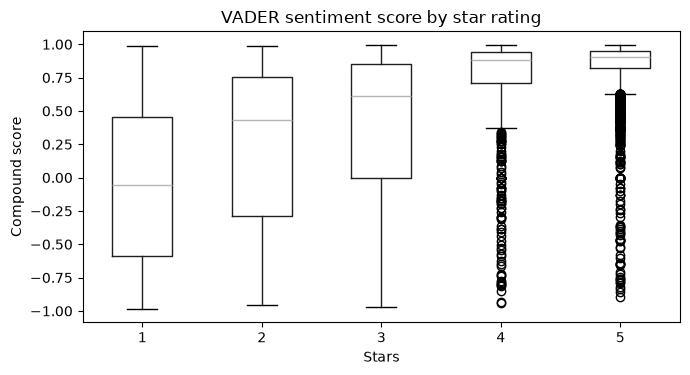

,mean,median,size
rating,,,
1,-0.06,-0.06,762
2,0.24,0.43,426
3,0.39,0.61,459
4,0.72,0.88,679
5,0.84,0.90,4698


In [26]:
ax = sample.boxplot(column='sentiment', by='rating', figsize=(7, 4), grid=False)
plt.suptitle('')
plt.title('VADER sentiment score by star rating')
plt.xlabel('Stars')
plt.ylabel('Compound score')
plt.tight_layout()
plt.show()

sample.groupby('rating')['sentiment'].agg(['mean', 'median', 'size']).round(2)

### Where VADER and the stars disagree

Reading the disagreements shows what VADER misses. The first group are 5-star reviews that VADER scores as negative, and the second are 1-star reviews that VADER scores as positive.

In [27]:
def show_examples(df, n=5):
    for _, r in df.sample(min(n, len(df)), random_state=1).iterrows():
        print(f"[{r['rating']} stars, VADER {r['sentiment']:+.2f}] {r['text_full'][:260]}")
        print()

print('5-star reviews scored negative by VADER:')
show_examples(sample[(sample['rating'] == 5) & (sample['sentiment'] < -0.3)])
print('1-star reviews scored positive by VADER:')
show_examples(sample[(sample['rating'] == 1) & (sample['sentiment'] > 0.3)])

5-star reviews scored negative by VADER:
[5 stars, VADER -0.79] Latest Update won't connect to Dropbox. The latest update doesn't play with Dropbox anymore ☹️. Love the app though, but no Dropbox sharing access makes it a dud.

[5 stars, VADER -0.77] Willing to make the product worse to promote their subscription. I paid for a nanit monitor and once the free trial expired on the app they put a permanent promotion that overlays the video telling you to upgrade to insights. You can't dismiss it, and it usual

[5 stars, VADER -0.71] Hate the update!. Apps reporting was great till they broke it - who needs feeding times above all? Why do you have to scroll through everything to get to patterns?

Booo, I’d like a refund, as your reporting got inconvenient, uninformative and essentially wort

[5 stars, VADER -0.65] MIRACLE. I’m a skeptic, I hate paying for apps. But this got my 6mo twins and 2yo to sleep at the SAME TIME. We went from chaos to 7pm bedtime in 48 hours. Worth EVERY PENNY!!

[5

### Sentiment per app, all reviews and last 24 months

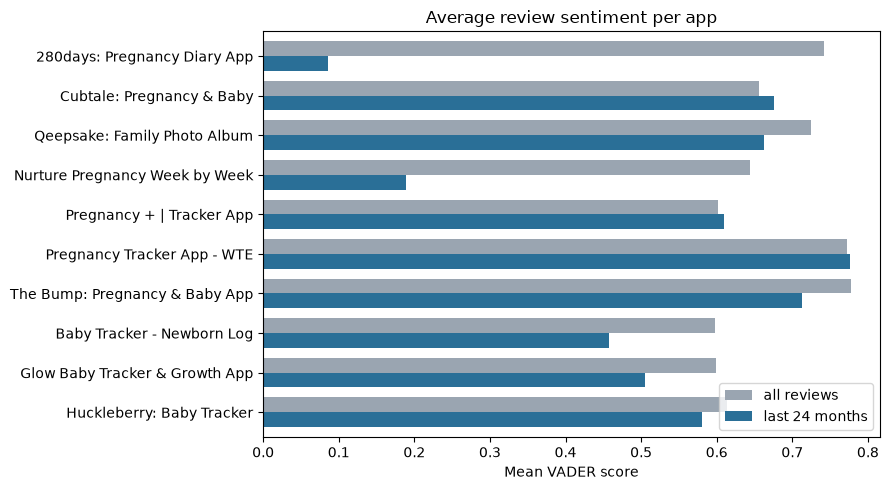

,low_pct_all,low_pct_last_24m,reviews_last_24m
app_name,,,
280days: Pregnancy Diary App,13.8,50.0,4
Cubtale: Pregnancy & Baby,18.3,12.8,180
Qeepsake: Family Photo Album,16.9,22.5,120
Nurture Pregnancy Week by Week,23.1,69.2,26
Pregnancy + | Tracker App,22.6,19.0,200
Pregnancy Tracker App - WTE,5.0,5.6,612
The Bump: Pregnancy & Baby App,7.8,11.8,297
Baby Tracker - Newborn Log,19.7,31.2,449
Glow Baby Tracker & Growth App,22.4,23.4,137


In [28]:
def mean_by_app(df):
    return df.groupby('app_name')['sentiment'].mean().reindex(APP_ORDER)

def low_share(df):
    return (df['rating'] <= 2).groupby(df['app_name']).mean().mul(100).reindex(APP_ORDER)

recent = sample[sample['recent']]
sentiment_compare = pd.DataFrame({'all reviews': mean_by_app(sample), 'last 24 months': mean_by_app(recent)})

ax = sentiment_compare.plot.barh(figsize=(9, 5), color={'all reviews': '#9aa5b1', 'last 24 months': '#2a6f97'}, width=0.75)
ax.invert_yaxis()
ax.set_xlabel('Mean VADER score')
ax.set_ylabel('')
ax.set_title('Average review sentiment per app')
plt.tight_layout()
plt.show()

low_compare = pd.DataFrame({'low_pct_all': low_share(sample), 'low_pct_last_24m': low_share(recent),
                            'reviews_last_24m': window_counts['last_24_months']}).round(1)
low_compare

In [29]:
pd.DataFrame({
    'sentiment_all': sample.groupby('segment')['sentiment'].mean(),
    'sentiment_last_24m': recent.groupby('segment')['sentiment'].mean(),
    'low_pct_all': (sample['rating'] <= 2).groupby(sample['segment']).mean() * 100,
    'low_pct_last_24m': (recent['rating'] <= 2).groupby(recent['segment']).mean() * 100,
}).round(2).reindex(SEGMENT_ORDER)

,sentiment_all,sentiment_last_24m,low_pct_all,low_pct_last_24m
segment,,,,
Direct,0.70,0.66,17.09,17.11
Category leader,0.71,0.72,13.88,11.01
Adjacent,0.60,0.53,20.33,25.10


## 13. What words separate happy and unhappy reviews

Before building a theme list, let the data speak. This counts, for every word and two-word phrase, the share of low-rated (1 to 2 star) and high-rated (4 to 5 star) reviews that contain it. The ratio shows which phrases belong mostly to one group. Counting reviews that contain a term, not total occurrences, stops one long review from dominating.

In [30]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

# Words that appear in nearly every review and separate nothing
STOP = list(ENGLISH_STOP_WORDS | {'app', 'apps', 'baby', 'pregnancy', 'pregnant', 'just', 'really', 'like', 'use',
                                  'using', 'im', 'ive', 'don', 'didn', 'doesn', 'isn', 'wasn', 'won', 've', 'll'})

def term_table(df):
    vec = CountVectorizer(ngram_range=(1, 2), stop_words=STOP, min_df=10, binary=True)
    X = vec.fit_transform(df['text_full'])
    low, high = (df['rating'] <= 2).to_numpy(), (df['rating'] >= 4).to_numpy()
    out = pd.DataFrame({'term': vec.get_feature_names_out(),
                        'low_docs': np.asarray(X[low].sum(axis=0)).ravel(),
                        'high_docs': np.asarray(X[high].sum(axis=0)).ravel()})
    out['low_pct'] = out['low_docs'] / low.sum() * 100
    out['high_pct'] = out['high_docs'] / high.sum() * 100
    out['ratio'] = (out['low_pct'] + 0.1) / (out['high_pct'] + 0.1)  # smoothed so very rare terms do not explode
    return out

terms_all = term_table(sample)
terms_recent = term_table(recent)
low_terms = terms_all[terms_all['low_docs'] >= 15].sort_values('ratio', ascending=False).head(25)
high_terms = terms_all[terms_all['high_docs'] >= 15].sort_values('ratio').head(25)

print(f"Low-rated reviews: {(sample['rating'] <= 2).sum()}, high-rated reviews: {(sample['rating'] >= 4).sum()}")
print('Phrases most typical of 1-2 star reviews:')
low_terms[['term', 'low_docs', 'low_pct', 'high_pct', 'ratio']].round(1).reset_index(drop=True)

Low-rated reviews: 1188, high-rated reviews: 5377
Phrases most typical of 1-2 star reviews:


,term,low_docs,low_pct,high_pct,ratio
0,useless,41,3.5,0.0,25.9
1,waste,30,2.5,0.0,19.1
2,disappointed,68,5.7,0.2,19.1
3,disappointing,46,3.9,0.1,17.3
4,ridiculous,29,2.4,0.1,16.3
5,garbage,17,1.4,0.0,15.3
6,awful,29,2.4,0.1,14.6
7,unusable,16,1.3,0.0,14.5
8,waste money,16,1.3,0.0,14.5
9,terrible,59,5.0,0.3,14.1


In [31]:
print('Phrases most typical of 4-5 star reviews (ratio is low/high, so smaller = more typical of happy reviews):')
high_terms[['term', 'high_docs', 'high_pct', 'low_pct', 'ratio']].round(2).reset_index(drop=True)

Phrases most typical of 4-5 star reviews (ratio is low/high, so smaller = more typical of happy reviews):


,term,high_docs,high_pct,low_pct,ratio
0,helps,351,6.53,0.17,0.04
1,love love,207,3.85,0.08,0.05
2,helps track,94,1.75,0.00,0.05
3,informative,325,6.04,0.25,0.06
4,love easy,85,1.58,0.00,0.06
5,definitely recommend,79,1.47,0.00,0.06
6,great love,142,2.64,0.08,0.07
7,super easy,72,1.34,0.00,0.07
8,helping,70,1.30,0.00,0.07
9,love great,64,1.19,0.00,0.08


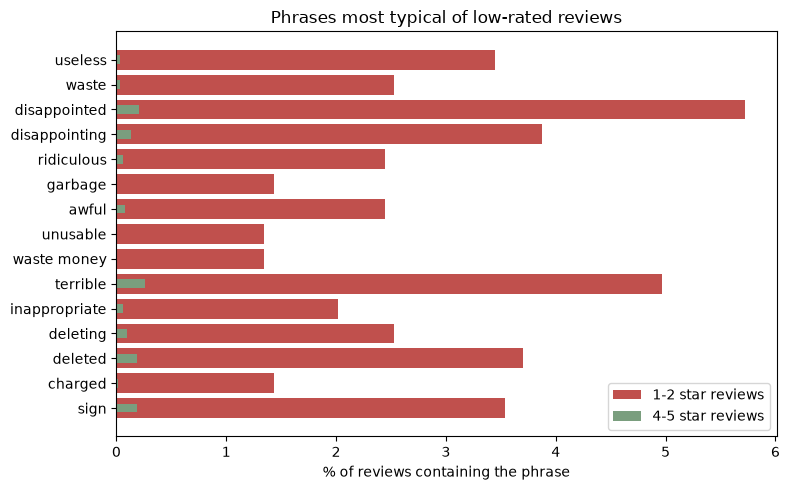

4 of the top 25 low-rated phrases are also in the top 25 for the last 24 months only:
deleted, disappointed, inappropriate, terrible


In [32]:
top = low_terms.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top['term'], top['low_pct'], color='#c0504d', label='1-2 star reviews')
ax.barh(top['term'], top['high_pct'], color='#7a9e7e', height=0.35, label='4-5 star reviews')
ax.set_xlabel('% of reviews containing the phrase')
ax.set_title('Phrases most typical of low-rated reviews')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

low_recent = terms_recent[terms_recent['low_docs'] >= 15].sort_values('ratio', ascending=False).head(25)
overlap = sorted(set(low_terms['term']) & set(low_recent['term']))
print(f'{len(overlap)} of the top 25 low-rated phrases are also in the top 25 for the last 24 months only:')
print(', '.join(overlap))

### Takeaways from sections 11 to 13

**VADER is reliable for happy reviews and weak for complaints.**
- Its label matches the star-based label for 82.1% of reviews, but that is carried by the 4-5 star reviews: 97.1% of them are scored positive.
- Only 44.4% of 1-2 star reviews are scored negative, and 47.6% are scored positive. Average scores are 0.84 at 5 stars but only -0.06 at 1 star.
- The disagreement examples explain why: reviewers use polite or mixed language ("Great app, but..."), and complaints about money or updates often contain positive words.
- So the star rating decides whether a review is positive or negative. The text is used to find out why, which is the theme analysis in the next step.

**Segments**
- Average sentiment is similar for Direct (0.70) and Category leaders (0.71), and lower for Adjacent (0.60).
- Low-rated share (1-2 stars): Adjacent 20.3% overall and 25.1% in the last 24 months (getting worse), Category leaders 13.9% falling to 11.0%, Direct 17.1% both ways.
- Some recent windows are too small to read: 280days has 4 reviews and Nurture 26 in the last 24 months, so their recent low-rated shares (50% and 69%) mean little.

**Words**
- Low-rated reviews are dominated by generic negative words (useless, terrible, disappointed), plus money words (charged, waste money, pay subscription, scam, refund, forced) and update words.
- High-rated reviews say helps, informative, easy, highly recommend, game changer and keeps track.
- Only 4 of the top 25 low-rated phrases are shared between the two windows, so single phrases are noisy. The theme tagging below groups related words, which should be steadier, and that will be tested.

## 14. Draft theme codebook (before tagging)

Built from reading about 100 reviews: 70 random 1-2 star reviews and 30 random 4-5 star reviews. Each theme has starter keywords. A review can carry several themes. Themes marked **J** matter most for a pregnancy journal like Wombloom.

### Complaint themes (mostly 1-2 star reviews)
| Code | Theme | What it captures | Starter keywords |
|---|---|---|---|
| N1 | Ads | Too many ads, ads at the top, inappropriate ad content, ads even for paying users | ad, ads, advert, sponsored |
| N2 | Pricing and subscription | Paywalled content, annual-only plans, auto-renewal, free app turning paid, refunds | subscription, paywall, premium, annual, per year, charged, renew, refund, free trial, scam, overpriced |
| N3 | Update regressions | A new layout or version made things worse | update, updated, new version, layout, redesign, old version, used to |
| N4 | Bugs and crashes | Freezing, crashing, lag, features not working | crash, freeze, glitch, bug, lag, won't load, black screen, not working |
| N5 | Data loss and sync | Lost entries or history, entries not saving, devices not syncing | lost, erased, disappeared, sync, not saving |
| N6 | Account and login | Forced account creation, sign-in loops, lockouts | login, log in, sign in, sign up, account, password |
| N7 | Content accuracy | Wrong due date, week or baby size, faulty timer | inaccurate, incorrect, wrong, due date, off by |
| N8 | Tone and inclusivity **J** | Scary or negative articles, weight-gain messaging, assumes straight or cis couples, ignores IVF or surrogacy, awkward pregnancy-loss flow | inclusive, heterosexual, straight, cis, IVF, surrogate, gain weight, miscarriage, loss |
| N9 | Community | Toxic boards, shaming, unwanted community prompts | community, forum, board, toxic, shaming, bullying |
| N10 | Privacy and data | Data sold or shared, AI using the data, camera access | privacy, sold, sell my, my data, camera, AI |
| N11 | Clutter and usability | Too busy, pop-ups, hard to find things, irrelevant prompts | cluttered, too much, confusing, hard to use, pop up, irrelevant |
| N12 | Support | No reply, slow help | customer service, support, no response, no reply |
| N13 | Sharing with partner **J** | Cannot share with a spouse or family, partner connection fails | share, sharing, partner, spouse, husband |

### Praise themes (mostly 4-5 star reviews)
| Code | Theme | What it captures | Starter keywords |
|---|---|---|---|
| P1 | Weekly information and reassurance | Informative articles, week-by-week guidance, peace of mind | informative, week by week, articles, learn, peace of mind, reassuring |
| P2 | Ease of use | Simple, intuitive | easy, user friendly, simple, intuitive |
| P3 | Tracking value | Logs, patterns, schedules that help | track, tracker, log, schedule, patterns, helps, game changer |
| P4 | Memories and emotional connection **J** | Prompts, keepsakes, looking back, bonding with the baby | memories, journal, prompts, remember, forget, bond, connected, look back, keepsake |
| P5 | Community support | Feeling less alone, other parents | community, other moms, not alone, forum, discussion |
| P6 | Value and free access | Free, no in-app purchases, worth the price | free, no in-app, worth, affordable |
| P7 | Sharing with family **J** | Partner, grandparents and family following along | share, partner, husband, grandma, grandmother, family |
| P8 | Visuals | 3D view, baby size comparisons, pictures | 3D, baby size, fruit, pictures, ultrasound, photos |

### How the tagging will be checked
- Tag every usable review with these rules.
- Hand-label 150 randomly chosen reviews, then report precision (how many tagged reviews really have the theme) and recall (how many real cases the rules found) for each theme.
- Rewrite any rule that scores poorly, and report the final scores in the notebook.
- Compare theme rates per app, for all reviews and for the last 24 months.

## 15. Tagging the reviews with themes

The rules live in `src/themes.py`. This section scores them against a hand-labeled sample, then tags all 7,024 usable reviews.

**What changed from the draft codebook (section 14)**
- **Themes are topics, not verdicts.** Complaint and praise pairs (ads, pricing, ease of use, community, sharing) became one topic each. A keyword cannot tell "great community" from "toxic community", and VADER showed text sentiment is unreliable here. The star rating says which it was, so each topic gets an average rating and a low-rated share.
- **Two themes were added** after reading the labeling sample: *Feature requests* (widgets, Apple Watch, Dynamic Island, missing totals) and *AI features* (several reviews react to new AI tools). There are now 19 themes.
- **Four topics were labeled only where praised** (tracking, information, memories, visuals), so they are scored on 4-5 star reviews only.

**How accuracy was checked**
- 150 reviews were hand-labeled before any rule was written: 80 rated 1-3 stars and 70 rated 4-5 stars. Low ratings were oversampled because complaint topics are rare in a random sample (76% of reviews are 5-star).
- The labels were made with AI assistance, not by a second person. A blind human spot-check would strengthen them.
- The sample is split in two. Rules were tuned on 100 "dev" reviews, then scored once on 50 held-out "test" reviews that were not touched while tuning. The test scores are the honest ones.
- Precision = of the reviews the rules tagged, how many really had the topic. Recall = of the reviews that really had it, how many the rules found.

In [33]:
import importlib
import sys

sys.path.insert(0, str(ROOT / 'src'))
import themes
importlib.reload(themes)

THEME_LABEL = {code: label for code, (label, _) in themes.THEMES.items()}
THEME_ORDER = list(themes.THEMES)

dev_scores = themes.evaluate('dev')
test_scores = themes.evaluate('test')
scores = (dev_scores[['theme', 'label', 'hand_labeled', 'precision', 'recall', 'f1']]
          .merge(test_scores[['theme', 'hand_labeled', 'precision', 'recall', 'f1']], on='theme', suffixes=('_dev', '_test')))
# A theme counts as reliable only if the test set has at least 3 real examples and the test F1 is at least 0.75
scores['tier'] = np.where((scores['hand_labeled_test'] >= 3) & (scores['f1_test'] >= 0.75), 'reliable', 'directional')
TIER = scores.set_index('theme')['tier']
scores.round(2)

,theme,label,hand_labeled_dev,precision_dev,recall_dev,f1_dev,hand_labeled_test,precision_test,recall_test,f1_test,tier
0,ADS,Ads,8,1.00,1.00,1.00,3,1.00,1.00,1.00,reliable
1,PRICE,Pricing and subscription,14,0.68,0.93,0.79,10,0.83,1.00,0.91,reliable
2,UPDATE,Updates and redesigns,23,0.85,0.96,0.90,8,0.78,0.88,0.82,reliable
3,BUGS,"Bugs, crashes and slowness",12,0.85,0.92,0.88,9,1.00,0.67,0.80,reliable
4,DATA,Data loss and sync,4,0.60,0.75,0.67,3,1.00,0.33,0.50,directional
5,ACCOUNT,Account and login,6,0.71,0.83,0.77,2,0.40,1.00,0.57,directional
6,ACCURACY,Accuracy of information,4,0.67,0.50,0.57,5,1.00,0.40,0.57,directional
7,INCLUSION,Inclusivity and tone,3,0.75,1.00,0.86,2,1.00,1.00,1.00,directional
8,COMMUNITY,Community,8,1.00,0.88,0.93,3,0.50,0.67,0.57,directional
9,PRIVACY,Privacy and data use,1,1.00,1.00,1.00,0,NaN,NaN,NaN,directional


Reliable themes (7): Ads, Pricing and subscription, Updates and redesigns, Bugs, crashes and slowness, Information and articles, Tracking and logging, Ease of use and design
Average test F1 of the reliable themes: 0.88
Test set, every theme pooled: precision 0.76, recall 0.84
Directional themes are too rare in the test set to score, or scored below 0.75. Use them as leads and read the reviews.


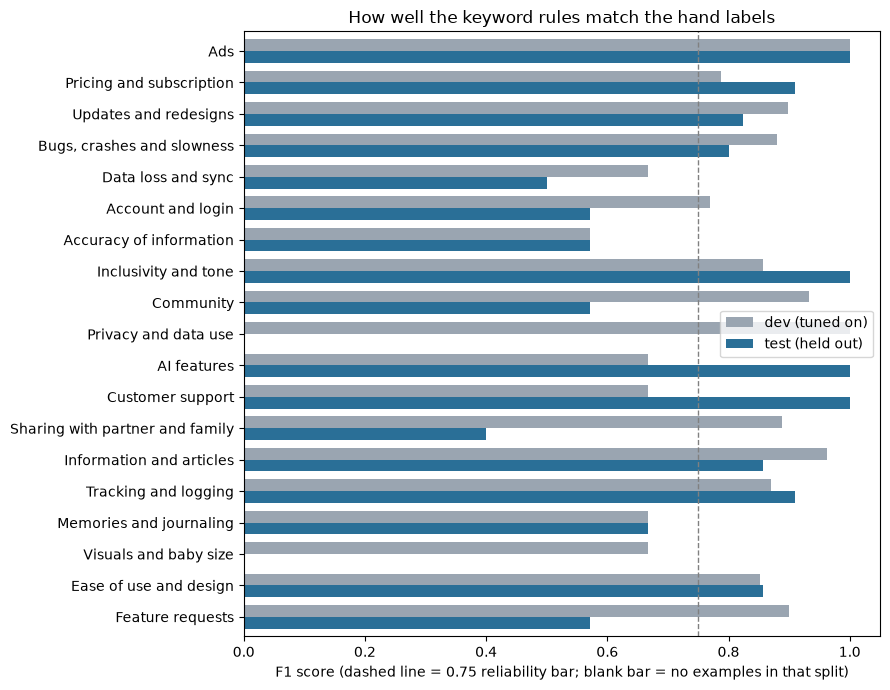

In [34]:
reliable = scores[scores['tier'] == 'reliable']
tp, fp, fn = (test_scores[c].sum() for c in ['true_pos', 'false_pos', 'false_neg'])
print(f"Reliable themes ({len(reliable)}): {', '.join(reliable['label'])}")
print(f"Average test F1 of the reliable themes: {reliable['f1_test'].mean():.2f}")
print(f'Test set, every theme pooled: precision {tp / (tp + fp):.2f}, recall {tp / (tp + fn):.2f}')
print('Directional themes are too rare in the test set to score, or scored below 0.75. Use them as leads and read the reviews.')

plot = scores.set_index('label')[['f1_dev', 'f1_test']].rename(columns={'f1_dev': 'dev (tuned on)', 'f1_test': 'test (held out)'})
ax = plot.plot.barh(figsize=(9, 7), color={'dev (tuned on)': '#9aa5b1', 'test (held out)': '#2a6f97'}, width=0.75)
ax.invert_yaxis()
ax.axvline(0.75, color='grey', linestyle='--', linewidth=1)
ax.set_xlabel('F1 score (dashed line = 0.75 reliability bar; blank bar = no examples in that split)')
ax.set_ylabel('')
ax.set_title('How well the keyword rules match the hand labels')
plt.tight_layout()
plt.savefig(FIGS / 'theme_rule_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

In [35]:
tags = themes.tag_reviews(sample)
tagged = pd.concat([sample, tags], axis=1)
tagged['n_themes'] = tags.sum(axis=1)
print(f"{(tagged['n_themes'] > 0).mean():.1%} of the {len(tagged):,} usable reviews carry at least one theme; median themes per review: {tagged['n_themes'].median():.0f}")

# Per-app rates, so large apps do not dominate. Recent window: only apps with at least 30 reviews in it.
MIN_RECENT = 30
recent_ok = tagged[tagged['recent']].groupby('app_name').filter(lambda g: len(g) >= MIN_RECENT)
print('Apps with too few reviews in the last 24 months, left out of the recent view:',
      sorted(set(APP_ORDER) - set(recent_ok['app_name'])))

86.4% of the 7,024 usable reviews carry at least one theme; median themes per review: 2
Apps with too few reviews in the last 24 months, left out of the recent view: ['280days: Pregnancy Diary App', 'Nurture Pregnancy Week by Week']


## 16. Feature gap matrix (Step 4 of the analysis plan)

Each cell is the share of an app's usable reviews that mention the topic. Columns marked with * are "directional" themes: their rules were too weak or too rare to score reliably, so read them as leads. Horizontal lines separate the Direct, Category leader and Adjacent apps.

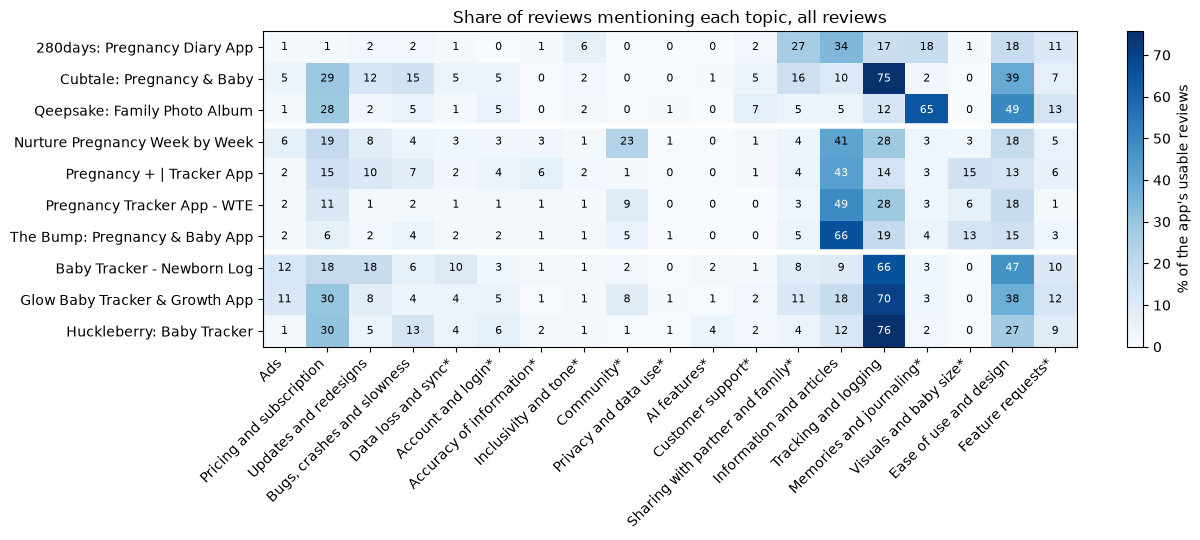

In [36]:
def app_rates(df):
    return df.groupby('app_name')[THEME_ORDER].mean().mul(100).reindex(APP_ORDER)

seg_of = tagged.drop_duplicates('app_name').set_index('app_name')['segment']

def heatmap(rates, title, filename=None):
    fig, ax = plt.subplots(figsize=(13, 5.5))
    values = rates.to_numpy()
    im = ax.imshow(values, cmap='Blues', aspect='auto', vmin=0)
    ax.set_xticks(range(len(THEME_ORDER)), [THEME_LABEL[c] + ('*' if TIER[c] == 'directional' else '') for c in THEME_ORDER], rotation=45, ha='right')
    ax.set_yticks(range(len(rates)), rates.index)
    top = np.nanmax(values)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v = values[i, j]
            if np.isnan(v):
                continue
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8, color='white' if v > top * 0.55 else 'black')
    segs = [seg_of[a] for a in rates.index]
    for k in range(1, len(segs)):
        if segs[k] != segs[k - 1]:
            ax.axhline(k - 0.5, color='white', linewidth=4)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label='% of the app\'s usable reviews')
    plt.tight_layout()
    if filename:
        plt.savefig(FIGS / filename, dpi=150, bbox_inches='tight')
    plt.show()

rates_all = app_rates(tagged)
heatmap(rates_all, 'Share of reviews mentioning each topic, all reviews', 'theme_heatmap_all.png')

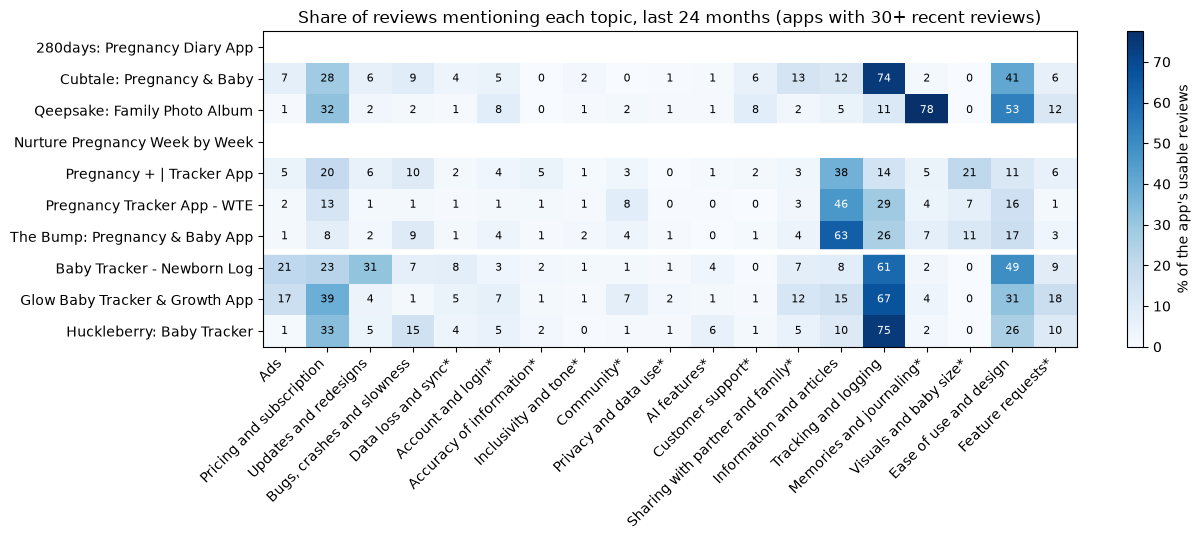

In [37]:
rates_recent = app_rates(recent_ok)  # apps with too few recent reviews are blank
heatmap(rates_recent, f'Share of reviews mentioning each topic, last 24 months (apps with {MIN_RECENT}+ recent reviews)', 'theme_heatmap_recent.png')

### How much each topic hurts

For each topic: how many reviews mention it, and how those reviews rate the app. A topic that is common and has a low average rating is a real pain point. A topic that is common with a high rating is something users value. Pooled across apps, so large apps weigh more here.

In [38]:
def theme_impact(df):
    rows = []
    for code in THEME_ORDER:
        m = df[code] == 1
        rows.append({'code': code, 'theme': THEME_LABEL[code], 'tier': TIER[code], 'reviews': int(m.sum()),
                     'pct_of_reviews': m.mean() * 100, 'avg_rating': df.loc[m, 'rating'].mean(),
                     'pct_low_rated': (df.loc[m, 'rating'] <= 2).mean() * 100})
    return pd.DataFrame(rows)

impact_all = theme_impact(tagged)
impact_recent = theme_impact(tagged[tagged['recent']])
baseline = pd.DataFrame({'avg_rating': [tagged['rating'].mean(), tagged.loc[tagged['recent'], 'rating'].mean()],
                         'pct_low_rated': [(tagged['rating'] <= 2).mean() * 100, (tagged.loc[tagged['recent'], 'rating'] <= 2).mean() * 100]},
                        index=['all reviews', 'last 24 months']).round(2)
print('Baseline for comparison (every usable review):')
display(baseline)

impact = impact_all.merge(impact_recent[['code', 'pct_of_reviews', 'avg_rating', 'pct_low_rated']], on='code', suffixes=('', '_24m'))
impact.drop(columns='code').sort_values('pct_low_rated', ascending=False).round(1).reset_index(drop=True)

Baseline for comparison (every usable review):


,avg_rating,pct_low_rated
all reviews,4.16,16.91
last 24 months,4.11,18.20


,theme,tier,reviews,pct_of_reviews,avg_rating,pct_low_rated,pct_of_reviews_24m,avg_rating_24m,pct_low_rated_24m
0,Ads,reliable,334,4.8,2.4,59.0,6.3,2.4,58.7
1,Privacy and data use,directional,37,0.5,2.5,56.8,0.7,2.4,61.1
2,Updates and redesigns,reliable,504,7.2,2.5,56.5,8.3,2.5,54.8
3,Account and login,directional,252,3.6,2.7,53.2,4.0,2.6,50.9
4,Customer support,directional,122,1.7,2.9,50.8,1.6,3.2,44.2
5,"Bugs, crashes and slowness",reliable,436,6.2,2.6,49.3,7.9,2.5,51.9
6,Accuracy of information,directional,119,1.7,2.6,47.9,1.7,2.5,54.3
7,AI features,directional,72,1.0,3.1,41.7,2.4,3.0,41.5
8,Data loss and sync,directional,250,3.6,3.2,38.4,3.4,3.1,40.0
9,Pricing and subscription,reliable,1403,20.0,3.4,36.5,22.9,3.6,29.7


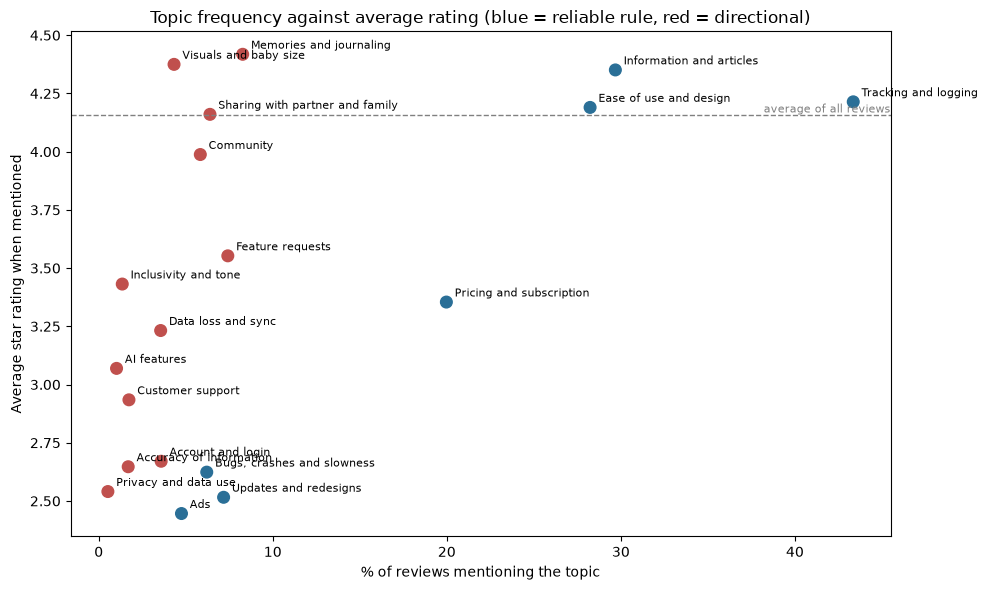

In [39]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = impact_all['tier'].map({'reliable': '#2a6f97', 'directional': '#c0504d'})
ax.scatter(impact_all['pct_of_reviews'], impact_all['avg_rating'], s=70, c=colors)
for _, r in impact_all.iterrows():
    ax.annotate(r['theme'], (r['pct_of_reviews'], r['avg_rating']), textcoords='offset points', xytext=(6, 4), fontsize=8)
ax.axhline(tagged['rating'].mean(), color='grey', linestyle='--', linewidth=1)
ax.text(ax.get_xlim()[1], tagged['rating'].mean(), ' average of all reviews', va='bottom', ha='right', color='grey', fontsize=8)
ax.set_xlabel('% of reviews mentioning the topic')
ax.set_ylabel('Average star rating when mentioned')
ax.set_title('Topic frequency against average rating (blue = reliable rule, red = directional)')
plt.tight_layout()
plt.savefig(FIGS / 'theme_frequency_vs_rating.png', dpi=150, bbox_inches='tight')
plt.show()

### Segment comparison

Average of the per-app rates within each segment, so each app counts once. The recent view leaves out apps with fewer than 30 recent reviews.

In [40]:
def segment_rates(df):
    per_app = df.groupby(['segment', 'app_name'])[THEME_ORDER].mean().mul(100)
    return per_app.groupby('segment').mean().reindex(SEGMENT_ORDER).T

segment_table = pd.concat({'all reviews': segment_rates(tagged), 'last 24 months': segment_rates(recent_ok)}, axis=1)
segment_table.index = [f"{THEME_LABEL[c]}{'*' if TIER[c] == 'directional' else ''}" for c in segment_table.index]
segment_table.round(1)

all reviews                           \
segment                               Direct Category leader Adjacent   
Ads                                      2.3             2.8      8.0   
Pricing and subscription                19.5            13.0     26.3   
Updates and redesigns                    5.6             5.5     10.2   
Bugs, crashes and slowness               7.4             4.2      7.9   
Data loss and sync*                      2.4             1.9      6.0   
Account and login*                       3.2             2.5      4.7   
Accuracy of information*                 0.5             2.8      1.1   
Inclusivity and tone*                    3.3             1.4      1.1   
Community*                               0.1             9.6      3.6   
Privacy and data use*                    0.4             0.5      0.6   
AI features*                             0.4             0.3      2.1   
Customer support*                        4.5             0.7      1.6   
Sharing with partner and family*        15.8             3.9      7.8   
Information and articles                16.3            49.6     13.0   
Tracking and logging                    34.8            22.4     70.7   
Memories and journaling*                28.4             3.6      2.5   
Visuals and baby size*                   0.4             9.2      0.2   
Ease of use and design                  35.4            16.0     37.1   
Feature requests*                       10.3             3.8     10.4   

                                 last 24 months                           
segment                                  Direct Category leader Adjacent  
Ads                                         3.8             2.7     12.9  
Pricing and subscription                   30.0            13.4     31.6  
Updates and redesigns                       4.3             3.1     13.4  
Bugs, crashes and slowness                  5.3             6.8      7.9  
Data loss and sync*                         2.4             1.2      5.6  
Account and login*                          6.7             2.9      5.0  
Accuracy of information*                    0.0             2.3      1.9  
Inclusivity and tone*                       1.5             1.4      0.8  
Community*                                  0.8             5.0      3.1  
Privacy and data use*                       0.7             0.4      1.2  
AI features*                                1.0             0.4      3.7  
Customer support*                           6.9             0.9      0.9  
Sharing with partner and family*            7.9             3.3      8.4  
Information and articles                    8.3            49.1     11.2  
Tracking and logging                       42.6            23.1     67.6  
Memories and journaling*                   39.6             5.3      2.7  
Visuals and baby size*                      0.0            13.2      0.1  
Ease of use and design                     47.2            14.6     35.7  
Feature requests*                           8.9             3.4     12.0

### Takeaways from sections 15 and 16

**How far to trust the tags**
- Seven themes are reliable (average test F1 0.88): ads, pricing, updates, bugs, information, tracking and ease of use. The other twelve are directional: they are rarer, so the 50 test reviews could not score them, or they scored below 0.75. Directional results are leads to check by reading reviews.
- Pooled over all themes on the test set, precision is 0.76 and recall 0.84, so roughly one tag in four is a false alarm.
- For tracking, information, memories and visuals, the rules were only validated on 4-5 star reviews. Their counts in low-rated reviews are not validated.

**What hurts most (reliable themes)**
- **Ads, updates and bugs** have the lowest ratings: average 2.4 to 2.6 stars, and 49% to 59% of the reviews that mention them are 1-2 star, against 17% for all reviews. They are mentioned by 5% to 7% of reviews each.
- **Pricing and subscription** is the biggest pain point by volume: 20% of all reviews, and 22.9% in the last 24 months. Its average rating is 3.4 stars, and 36.5% of its reviews are low-rated.
- Directional leads with even lower ratings but few reviews: privacy (57% low-rated, 37 reviews), account and login (53%), customer support (51%), accuracy (48%) and AI features (42%).

**What users value**
- Information and articles (4.4 stars), tracking (4.2) and ease of use (4.2) are the most frequent topics and sit at or above the 4.16 average. Memories and journaling also averages 4.4 stars (581 reviews), so people who write about it are happy.

**Segments**
- **Adjacent baby trackers** carry the most complaints: ads in 8.0% of reviews (12.9% in the last 24 months), updates 10.2% (13.4%) and pricing 26.3% (31.6%). Their praise is almost all about tracking (71%).
- **Category leaders** are about information (50% of reviews), with community (9.6%) and baby-size visuals (9.2%). They mention ads (2.8%), bugs (4.2%) and pricing (13.0%) less often than the other two segments.
- **Direct competitors** stand out for memories and journaling (28%, rising to 40% recently), sharing with a partner or family (15.8%), and customer support (4.5%, the highest). Pricing complaints rose from 19.5% to 30.0% in the last 24 months.

**Direct competitors are not one group**
- Qeepsake is the only true memory-keeping app (65% of its reviews mention memories and journaling). Cubtale behaves like a tracker (75% tracking), and 280days is about information (34%) and sharing (27%). The Direct segment was assigned by keywords in section 3, so treat it as three different cases. Qeepsake is the closest evidence for Wombloom's concept.

## 17. Conclusions and actions: what Wombloom should do

This section turns the analysis into decisions. It is meant to be the input for the app feature plan. Wombloom is not released yet, so everything here is a choice to make before launch.

**The research in six points**
1. **Money and trust cause the unhappiest reviews.** Ads, updates, bugs and pricing are the topics with the lowest ratings, and pricing is also the most common of them (20% of all reviews mention it, and 36.5% of those are 1-2 star).
2. **A lost entry is the failure a journal cannot afford.** Reviews describe lost photos and years of entries after a sign-out or an update. This is a directional finding, but the stakes are higher for a journal than for a feeding log.
3. **The big pregnancy apps compete on information** (50% of their reviews). They barely touch journaling (3.6%).
4. **The journaling apps are few and narrow.** People who write about memories and journaling are happy (4.4 stars, 581 reviews), mostly in Qeepsake, which is a family photo album and not a pregnancy journal.
5. **Sharing with a partner or family is valued** (4.2 stars) and is also a billing irritation.
6. **Inclusivity is a small but low-rated topic**, and a journal competitor (280days) is criticized for it.

**How strong each conclusion is**
- **Strong:** the topic is a reliable rule (test F1 of 0.75 or more) and the pattern holds in both time windows.
- **Moderate:** the topic is a directional rule, but the pattern is consistent and the quotes support it.
- **Exploratory:** under about 130 mentions. Treat as a hypothesis to test in interviews.

In [41]:
ACTION_TOPICS = ['ADS', 'PRICE', 'UPDATE', 'BUGS', 'DATA', 'ACCOUNT', 'MEMORIES', 'SHARING', 'INCLUSION', 'REQUEST',
                 'SUPPORT', 'ACCURACY', 'AI', 'PRIVACY']
seg_all = segment_rates(tagged)  # rows = theme codes, columns = segments (average of per-app rates)

evidence = (impact.set_index('code').loc[ACTION_TOPICS, ['theme', 'tier', 'reviews', 'pct_of_reviews', 'pct_of_reviews_24m',
                                                         'avg_rating', 'pct_low_rated', 'pct_low_rated_24m']]
            .join(seg_all.loc[ACTION_TOPICS].add_prefix('% in ')))
evidence = evidence.rename(columns={'pct_of_reviews': '% of reviews', 'pct_of_reviews_24m': '% last 24m',
                                    'avg_rating': 'avg stars', 'pct_low_rated': '% 1-2 star',
                                    'pct_low_rated_24m': '% 1-2 star last 24m'})
print(f"Baseline: {(tagged['rating'] <= 2).mean() * 100:.1f}% of all usable reviews are 1-2 stars; average rating {tagged['rating'].mean():.2f}")
evidence.round(1).reset_index(drop=True)

Baseline: 16.9% of all usable reviews are 1-2 stars; average rating 4.16


,theme,tier,reviews,% of reviews,% last 24m,avg stars,% 1-2 star,% 1-2 star last 24m,% in Direct,% in Category leader,% in Adjacent
0,Ads,reliable,334,4.8,6.3,2.4,59.0,58.7,2.3,2.8,8.0
1,Pricing and subscription,reliable,1403,20.0,22.9,3.4,36.5,29.7,19.5,13.0,26.3
2,Updates and redesigns,reliable,504,7.2,8.3,2.5,56.5,54.8,5.6,5.5,10.2
3,"Bugs, crashes and slowness",reliable,436,6.2,7.9,2.6,49.3,51.9,7.4,4.2,7.9
4,Data loss and sync,directional,250,3.6,3.4,3.2,38.4,40.0,2.4,1.9,6.0
5,Account and login,directional,252,3.6,4.0,2.7,53.2,50.9,3.2,2.5,4.7
6,Memories and journaling,directional,581,8.3,6.8,4.4,12.0,13.7,28.4,3.6,2.5
7,Sharing with partner and family,directional,449,6.4,5.7,4.2,16.0,15.1,15.8,3.9,7.8
8,Inclusivity and tone,directional,95,1.4,1.1,3.4,35.8,27.6,3.3,1.4,1.1
9,Feature requests,directional,521,7.4,6.9,3.6,21.3,23.9,10.3,3.8,10.4


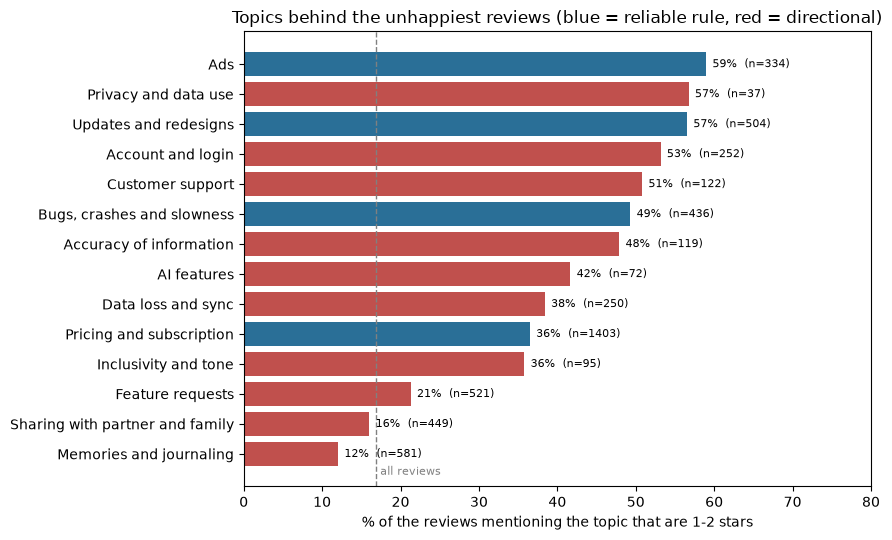

In [42]:
chart = evidence.sort_values('% 1-2 star')
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(chart['theme'], chart['% 1-2 star'], color=chart['tier'].map({'reliable': '#2a6f97', 'directional': '#c0504d'}))
for y, (pct, n) in enumerate(zip(chart['% 1-2 star'], chart['reviews'])):
    ax.text(pct + 0.8, y, f'{pct:.0f}%  (n={n})', va='center', fontsize=8)
ax.axvline((tagged['rating'] <= 2).mean() * 100, color='grey', linestyle='--', linewidth=1)
ax.text((tagged['rating'] <= 2).mean() * 100 + 0.5, -0.7, 'all reviews', color='grey', fontsize=8)
ax.set_xlim(0, 80)
ax.set_xlabel('% of the reviews mentioning the topic that are 1-2 stars')
ax.set_ylabel('')
ax.set_title('Topics behind the unhappiest reviews (blue = reliable rule, red = directional)')
plt.tight_layout()
plt.savefig(FIGS / 'action_topics_low_rated.png', dpi=150, bbox_inches='tight')
plt.show()

### 17.1 Where the opening is

| Segment | What users talk about most | Main complaints | What it leaves open |
|---|---|---|---|
| Category leaders (WTE, Pregnancy+, The Bump, Nurture) | Information and articles (50% of reviews), community (9.6%), baby-size visuals (9.2%) | Pricing (13.0%), some accuracy and community-tone issues (directional) | Very little journaling (3.6% of reviews) |
| Baby trackers (Huckleberry, Glow Baby, Baby Tracker) | Tracking and logging (71%), ease of use (37%) | Pricing (26.3%), updates (10.2%), ads (8.0%) and data loss (6.0%). Pricing, updates and ads all rose in the last 24 months | They are used after birth, not for pregnancy |
| Journal-style apps (Qeepsake, Cubtale, 280days) | Memories and journaling (28%, 40% recently), sharing (15.8%) | Pricing (19.5%, rising to 30.0%), customer support (4.5%), inclusivity (3.3%) | Small and narrow: Qeepsake is a post-birth family album, Cubtale is mostly a tracker, 280days has few reviews |

**The opening (moderate evidence):** among the 10 apps studied, none combines pregnancy-week journaling with an ad-free, private, inclusive experience and fair pricing. The leaders do information, the trackers do logging, and the journal apps are small. A suggested positioning to test: *a private, ad-free pregnancy journal that keeps your memories safe and lets your partner and family follow along.*

### 17.2 Action plan

Priority: **P0** decide before building, because it shapes the whole product. **P1** the features that differentiate Wombloom. **P2** later or lower relevance. **Avoid** things that reviewers punish.

| # | Priority | Action | Why (from the data) | Strength |
|---|---|---|---|---|
| A1 | P0 | **Keep the app ad-free, and never show ads to paying users.** | Ads appear in 4.8% of reviews and 59% of those are 1-2 star. Baby trackers went from 8.0% to 12.9% of reviews mentioning ads in the last 24 months. Many reviews complain about ads after paying. | Strong |
| A2 | P0 | **Set a simple, transparent pricing model before launch.** Keep the core journal free, offer a monthly plan as well as annual, send a renewal reminder, make cancelling and refunds easy, and never move a free feature behind a paywall later. | Pricing is in 20.0% of reviews (22.9% in the last 24 months) and 36.5% of them are 1-2 star. Journal apps went from 19.5% to 30.0%. The anger is about annual-only plans, surprise renewals and features that used to be free. | Strong |
| A3 | P0 | **Never lose a user's entries.** Store entries on the device first, back up automatically (for example iCloud), offer an export, and test the sign-out and update paths. | Bugs: 6.2% of reviews, 49% 1-2 star. Data loss: 3.6% of reviews, 38% 1-2 star. Reviewers describe losing photos and years of entries. | Strong (bugs), moderate (data loss) |
| A4 | P0 | **Release updates carefully.** Avoid big redesigns for existing users, roll out gradually, explain changes, and keep navigation stable. | Updates and redesigns: 7.2% of reviews and 56.5% are 1-2 star. Baby trackers rose from 10.2% to 13.4%. | Strong |
| B1 | P1 | **Build the core around pregnancy-week journaling.** Weekly prompts that match the stage of pregnancy, easy photo entries (including several photos per entry), and a timeline to look back on. | Memories and journaling: 581 reviews at 4.4 stars, 28% of reviews on average across the three journal apps and 65% of Qeepsake's. Leaders: 3.6%. Qeepsake users complain about prompts that start before birth and are repetitive or not age-appropriate. | Moderate |
| B2 | P1 | **Let a partner and family follow along, included in the base plan.** An invite or read-only view, not an extra paid seat. | Sharing: 449 reviews at 4.2 stars, 15.8% of reviews on average across the journal apps. One reviewer says the subscription cannot be shared with a partner, so they would have to buy it twice. | Moderate |
| B3 | P1 | **Make the app optional-account.** Let people start writing with no sign-in, and offer an account only for backup and sync. | Account and login: 252 reviews, 53% 1-2 star. Reviewers describe lockouts and sign-in on every launch, and one praises an app with no cloud account. | Moderate |
| B4 | P1 | **Be inclusive by default.** Neutral language, flexible partner roles, a due-date override for IVF and surrogacy, support for twins and early births, teen-friendly sign-up, and a gentle pregnancy-loss experience. | Inclusivity: only 95 reviews (1.4%) but 3.4 stars, and 35.8% 1-2 star (27.6% in the last 24 months). A journal competitor is criticized for assuming heterosexual couples. Reviewers also praise miscarriage support. | Exploratory |
| B5 | P1 | **Make keepsakes honest.** Offer a digital export first. If you sell a printed book later, show the full price including shipping and duty before checkout, and let credits roll over. | Qeepsake reviews complain about book fees and duty in Canada, credits that expire, and print quality. | Exploratory |
| C1 | P2 | **Add iOS quick-access features later.** Widgets, Apple Watch, Live Activities or Dynamic Island, and typed times. | Feature requests: 521 reviews at 3.6 stars, but almost all from baby-tracker users. The one journal-specific request is several photos per entry. | Moderate (for trackers), low relevance |
| C2 | P2 | **Offer in-app support and easy refunds.** | Customer support: 122 reviews, 51% 1-2 star. Journal apps mention it most (4.5%). | Exploratory |
| C3 | P2 | **Let the user set and change their due date, and say where any baby-size data comes from.** | Accuracy: 119 reviews, 48% 1-2 star. Wrong weeks and sizes, and IVF due dates that cannot be changed. | Exploratory |
| D1 | Avoid | **Do not force AI features.** If you add any, make them optional and clearly labeled. | AI: 72 reviews, 42% 1-2 star. Reviewers object to AI they cannot turn off. | Exploratory |
| D2 | Avoid | **Do not sell or share pregnancy data, and say plainly what you collect.** | Privacy: only 37 reviews but 57% 1-2 star. Reviewers mention data sold and emails from third parties. | Exploratory |
| D3 | Avoid | **Do not try to out-publish the leaders on articles.** | Leaders put 50% of their reviews on information. Compete on the journal, where they are thin. | Judgment call from the market map |

### 17.3 A starting point for the feature plan

This is a suggested starting point built from the actions above, not a specification.

**Release 1: the foundation (A1 to A4, B1, B3)**
- Pregnancy journal with weekly prompts and photo entries
- Works without an account, with entries stored on the device
- Automatic backup and an export option
- No ads, one simple pricing model decided up front
- Inclusive language and a changeable due date from day one

**Release 2: what people share (B2, B4, B5)**
- Partner and family invite, included in the base plan
- Pregnancy-loss and other sensitive-situation support
- Digital keepsake export

**Release 3: polish (C1 to C3)**
- Widgets and quick-add, support tools, printed books if the first two releases show demand

Everything in Release 1 is either strong evidence or a decision that is cheapest to make before launch.

### 17.4 Evidence: what reviewers said

Short excerpts from public reviews, each shown with the app and star rating. No reviewer names or IDs are stored. These are quotes selected to illustrate the numbers, not a count of how common each view is.

**Ads and pricing (A1, A2)**
> "I purchased premium and my caregivers all experience pop up ads." (Glow Baby, 1 star)
>
> "Don’t expect to pay for the premium service and not still get ads shoved down your throat cause you will!" (Glow Baby, 1 star)
>
> "The app is forcing you to buy annual subscription when I just need for a few months" (Glow Baby, 1 star)
>
> "Not impressed just auto renewed my subscription without emailing me ahead of time." (Qeepsake, 1 star)
>
> "They took free features away and put them behind a paywall" (Cubtale, 1 star)
>
> "Be upfront about what’s paywalled." (Huckleberry, 1 star)

**Updates (A4)**
> "I would GLADLY pay for this if it would give me back the easy to use version." (Baby Tracker, 1 star)
>
> "Please go back to the previous look. I wish I had auto updates turned off." (Baby Tracker, 2 stars)

**Lost entries (A3)**
> "I was signed out for some reason today and now all of my pictures and journal entries are gone." (The Bump, 2 stars)
>
> "years and years of data gone! They charged my card for renewal and so I am paying for NOTHING!" (Qeepsake, 1 star)
>
> "Logged me out for no reason and when I logged back in all my data from the first two weeks of my child’s life was erased." (The Bump, 1 star)

**Accounts (B3)**
> "This new update makes me sign in every time and it’s very inconvenient as I don’t have time to sign in while feeding and changing a baby." (Huckleberry, 4 stars)
>
> "No cloud account to sign in to, it just opens right away and works." (Baby Tracker, 5 stars)

**Journaling: what works and what does not (B1, B5)**
> "It’s so much easier to do than making an actual album." (Qeepsake, 5 stars)
>
> "They remind me of things that happened years ago that I would have forgotten if I hadn’t been using it." (Qeepsake, 5 stars)
>
> "The questions obviously I couldn’t answer, and then after my baby was born the questions weren’t age appropriate." (Qeepsake, 2 stars)
>
> "Was cute at first. But now I am getting the same questions over and over again." (Qeepsake, 2 stars)
>
> "After reading about the book fees I will cancel don’t want to deal with duty and exchange!!!" (Qeepsake, 1 star)
>
> "However, the $65 credit expires annually rather than rolling over to be used in the future." (Qeepsake, 1 star)
>
> "Ability to add more than 1 pic to a journal entry." (Qeepsake, 4 stars)

**Sharing with partner and family (B2)**
> "your subscription is non-transferable to your partner. So you’d have to buy it twice, which we’re not going to do." (Glow Baby, 4 stars)
>
> "My favorite part of the app is the ability to share with family members and other caregivers." (Cubtale, 5 stars)
>
> "Have enjoyed following my daughter’s pregnancy with this app" (The Bump, 5 stars, from a grandmother)

**Inclusivity (B4)**
> "Really disappointing that this is designed only for heterosexual white couples." (280days, 1 star)
>
> "The only thing I wish for is that there was a choice to change gender for other partner." (280days, 3 stars)
>
> "As an intended parent with a GC and using ivf, this app doesn’t track the time properly even though I put in our correct due date, it is a week ahead." (Pregnancy+, 2 stars)
>
> "If your signed up as a father you don’t get the same experience" (Pregnancy+, 1 star)
>
> "People under the age of 16 are having baby’s and it’s not fair that we don’t get the opportunity to track our pregnancy’s because of your age requirement." (Nurture, 1 star)
>
> "When I had a miscarriage earlier this year, I discovered the miscarriage support groups and articles, and it was a comfort and a help to find more information on miscarriage." (WTE, 5 stars)

**Privacy, AI and support (D1, D2, C2)**
> "They now require the user to agree to allow their info to be sold and shared in order to use the app." (Pregnancy+, 1 star)
>
> "Everything is an upsell. Or a subscription, or asking for more data. I immediately got emails from third party companies." (WTE, 1 star)
>
> "Not happy with the addition of more AI into an app that no one asked for." (Huckleberry, 1 star)
>
> "I’ve sent multiple emails to get support and haven’t received a response." (Huckleberry, 1 star)
>
> "I tried to get a refund and they denied me refund." (Glow Baby, 1 star)

### 17.5 What this research cannot tell you

- **It describes other apps' users.** None of these reviewers used Wombloom, and people who write reviews lean toward strong opinions.
- **iOS only, US and Canada only.** Google Play was skipped.
- **Recent reviews only.** The feed gives the newest 500 per app and country, and the time windows differ by app.
- **The journal-app evidence is thin.** Qeepsake provides most of it, and the Direct group is three different apps. Cubtale and 280days have few reviews, and 280days has too few recent reviews to be included in any last-24-months figure for the journal apps.
- **Directional topics are leads.** Inclusivity, privacy, AI, support and accuracy each have fewer than about 130 mentions, and their rules are less accurate.
- **It cannot say what people would pay for or build.** It shows what annoys them in existing apps. It does not prove demand for a new feature.

### 17.6 What to do next to firm this up

1. **Interview 5 to 10 expecting or new parents.** Include people who keep a pregnancy journal, people who used Qeepsake or similar apps, and people from LGBTQ+ and IVF or surrogacy families, since the inclusivity evidence is the thinnest.
2. **Test the pricing idea.** Show two or three pricing options and ask what feels fair. Pricing is the most common complaint.
3. **Check the competitors' current pricing and features directly** (App Store listings and websites), so the plan reflects today and not only the reviews.
4. **Read more reviews for the thin topics** (inclusivity, privacy, accounts) before treating them as requirements.
5. **Add Google Play later** if Android becomes part of the launch plan. The pipeline already has a `platform` column for it.

## 18. Prioritization: from evidence to a ranked list

Section 17 ranked the actions by judgment. This section scores them with an explicit model, then tests whether the answer depends on my assumptions. The model is in `src/prioritize.py`.

**Score = w1 x Reach + w2 x Impact + w3 x Confidence - w4 x Effort**, each part scaled 0 to 1.

| Part | Meaning | How it is measured |
|---|---|---|
| Reach | How many reviews raise the topic | Share of reviews mentioning it, averaged per app so big apps do not dominate |
| Impact | Stars at stake | How far the average rating of reviews mentioning the topic is from the overall average, in either direction |
| Confidence | How far to trust the evidence | 1.0 for a reliable keyword rule. For a directional rule: 0.6 with 250+ mentions, 0.4 with 100 to 249, 0.2 under 100. An action using several topics takes its weakest one |
| Effort | Cost to build | Small, medium or large (1 to 3). An estimate made with AI assistance, not measured, so it is flagged as an assumption. The dashboard lets a reader change it |

**Default weights** are 0.25 reach, 0.35 impact, 0.25 confidence and 0.15 effort. They are assumptions, not facts, which is why the ranking is stress-tested below. Two actions with no clean review topic (honest keepsakes and "do not out-publish the leaders") are left out of the scoring.

In [43]:
sys.path.insert(0, str(ROOT / 'src'))
import prioritize
importlib.reload(prioritize)

DASH = ROOT / 'data' / 'aggregates'
REGISTERS = ROOT / 'data' / 'registers'
register = pd.read_csv(REGISTERS / 'actions_register.csv')
action_evidence = pd.read_csv(DASH / 'action_evidence.csv')
REGISTER_COLS = ['action_id', 'priority', 'action', 'narrative_order', 'strength', 'v1_status', 'v1_evidence']

def scored(window, weights=None, efforts=None):
    ev = action_evidence[action_evidence['window'] == window]
    return prioritize.score_actions(ev, weights, efforts).merge(register[REGISTER_COLS], on='action_id').sort_values('rank')

rank_all, rank_recent = scored('all'), scored('last_24m')
rank_all[['rank', 'action_id', 'action', 'priority', 'score', 'reach', 'impact', 'confidence', 'effort_used', 'tier', 'n_reviews']].round(2).reset_index(drop=True)

,rank,action_id,action,priority,score,reach,impact,confidence,effort_used,tier,n_reviews
0,1,A4,Release updates carefully (no surprise redesigns),P0,0.67,0.35,0.96,1.0,1,reliable,504
1,2,A2,Set a simple transparent pricing model before ...,P0,0.66,1.00,0.47,1.0,1,reliable,1403
2,3,A1,Keep the app ad-free; never show ads to paying...,P0,0.65,0.20,1.00,1.0,1,reliable,334
3,4,B3,Make the account optional (start with no sign-in),P1,0.49,0.16,0.87,0.6,1,directional,252
4,5,A3,Never lose a user's entries (device first + ba...,P0,0.45,0.46,0.76,0.6,2,directional,646
5,6,C3,Let the user change the due date and state sou...,P2,0.42,0.06,0.88,0.4,1,directional,119
6,7,D2,Do not sell or share pregnancy data; say plain...,Avoid,0.38,0.00,0.94,0.2,1,directional,37
7,8,C2,Offer in-app support and easy refunds,P2,0.37,0.09,0.71,0.4,1,directional,122
8,9,D1,Do not force AI features,Avoid,0.28,0.02,0.63,0.2,1,directional,72
9,10,B1,Build the core around pregnancy-week journaling,P1,0.27,0.55,0.15,0.6,2,directional,581


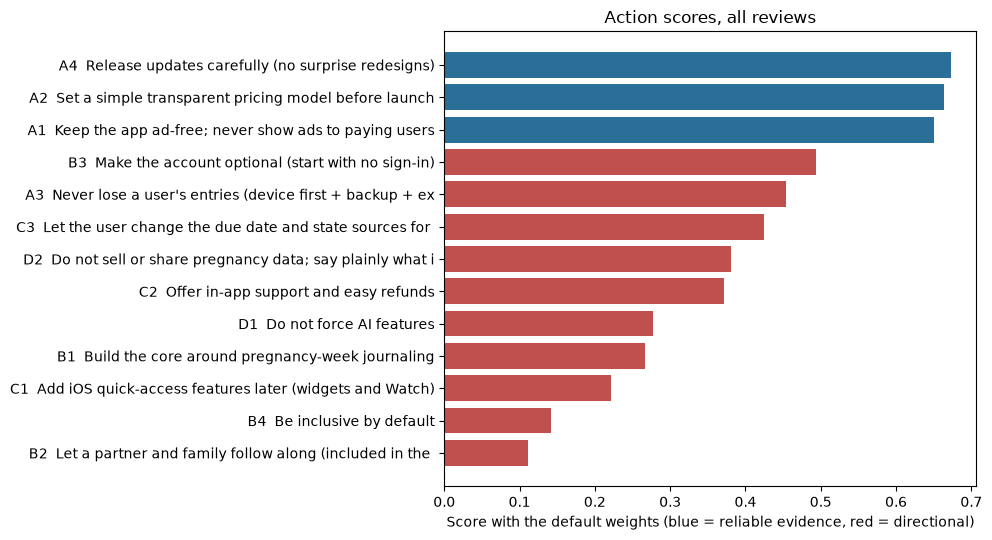

In [44]:
plot = rank_all.iloc[::-1]
colors = plot['tier'].map({'reliable': '#2a6f97', 'directional': '#c0504d'})
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(plot['action_id'] + '  ' + plot['action'].str.slice(0, 55), plot['score'], color=colors)
ax.set_xlabel('Score with the default weights (blue = reliable evidence, red = directional)')
ax.set_title('Action scores, all reviews')
plt.tight_layout()
plt.savefig(FIGS / 'action_scores.png', dpi=150, bbox_inches='tight')
plt.show()

### Does the ranking survive different weights?

The weights are my assumptions, so this redraws all four at random 5,000 times and records where each action lands. A short bar near the top means the action is a robust priority. A long bar means its rank depends on what you value.

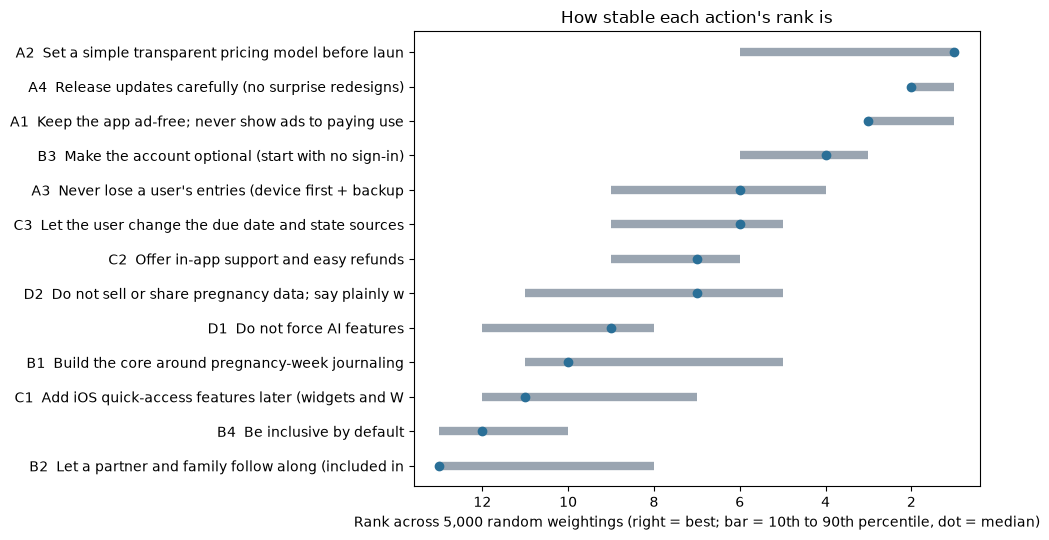

,action_id,action,median_rank,pct_in_top3,pct_in_top5
0,A2,Set a simple transparent pricing model before ...,1.0,84.4,88.1
1,A4,Release updates carefully (no surprise redesigns),2.0,99.0,100.0
2,A1,Keep the app ad-free; never show ads to paying...,3.0,93.0,98.6
3,B3,Make the account optional (start with no sign-in),4.0,10.2,85.3
4,A3,Never lose a user's entries (device first + ba...,6.0,4.0,47.4
5,C3,Let the user change the due date and state sou...,6.0,0.0,45.2
6,C2,Offer in-app support and easy refunds,7.0,0.0,3.2
7,D2,Do not sell or share pregnancy data; say plain...,7.0,5.3,13.7
8,D1,Do not force AI features,9.0,0.0,0.0
9,B1,Build the core around pregnancy-week journaling,10.0,4.1,17.2


In [45]:
ev_all = action_evidence[action_evidence['window'] == 'all']
stab = prioritize.rank_stability(ev_all).merge(register[['action_id', 'action']], on='action_id')

fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(stab))
ax.hlines(y, stab['best_rank'], stab['worst_rank'], color='#9aa5b1', linewidth=6)
ax.scatter(stab['median_rank'], y, color='#2a6f97', zorder=3)
ax.set_yticks(y, stab['action_id'] + '  ' + stab['action'].str.slice(0, 50))
ax.invert_yaxis()
ax.invert_xaxis()
ax.set_xlabel('Rank across 5,000 random weightings (right = best; bar = 10th to 90th percentile, dot = median)')
ax.set_title('How stable each action\'s rank is')
plt.tight_layout()
plt.savefig(FIGS / 'rank_stability.png', dpi=150, bbox_inches='tight')
plt.show()

stab[['action_id', 'action', 'median_rank', 'pct_in_top3', 'pct_in_top5']].round(1).reset_index(drop=True)

In [46]:
# Does the answer depend on the time window or on effort? Compare the top 5 and a no-effort variant.
no_effort = scored('all', weights={'reach': 0.25, 'impact': 0.35, 'confidence': 0.25, 'effort': 0.0})
check = (rank_all[['action_id', 'rank']].rename(columns={'rank': 'rank_all_default'})
         .merge(rank_recent[['action_id', 'rank']].rename(columns={'rank': 'rank_last_24m'}), on='action_id')
         .merge(no_effort[['action_id', 'rank']].rename(columns={'rank': 'rank_ignoring_effort'}), on='action_id'))
# Rank my narrative order among the same 13 scored actions, so both rankings are on the same footing
narrative = register.set_index('action_id').loc[check['action_id'], 'narrative_order']
check['narrative_rank'] = check['action_id'].map(narrative.rank(method='min').astype(int))
print('Top 5, all reviews:        ', ', '.join(rank_all['action_id'].head(5)))
print('Top 5, last 24 months:     ', ', '.join(rank_recent['action_id'].head(5)))
print('Top 5, ignoring effort:    ', ', '.join(no_effort['action_id'].head(5)))
check.merge(register[['action_id', 'action']], on='action_id').sort_values('rank_all_default').reset_index(drop=True)

Top 5, all reviews:         A4, A2, A1, B3, A3
Top 5, last 24 months:      A1, A4, A2, A3, B3
Top 5, ignoring effort:     A4, A2, A1, A3, B3


,action_id,rank_all_default,rank_last_24m,rank_ignoring_effort,narrative_rank,action
0,A4,1,2,1,4,Release updates carefully (no surprise redesigns)
1,A2,2,3,2,2,Set a simple transparent pricing model before ...
2,A1,3,1,3,1,Keep the app ad-free; never show ads to paying...
3,B3,4,5,5,7,Make the account optional (start with no sign-in)
4,A3,5,4,4,3,Never lose a user's entries (device first + ba...
5,C3,6,6,6,11,Let the user change the due date and state sou...
6,D2,7,7,7,13,Do not sell or share pregnancy data; say plain...
7,C2,8,9,8,10,Offer in-app support and easy refunds
8,D1,9,8,11,12,Do not force AI features
9,B1,10,10,10,5,Build the core around pregnancy-week journaling


### Where the model and my judgment disagree

The model measures how many stars an app loses by failing at a topic. It cannot see whether a topic is a chance to stand out. So this view adds a second lens: **differentiation**, which is how much more the journal-style apps (Direct) talk about a topic than the leaders and baby trackers do. A ratio of 2 or more means the journal apps over-index on it.

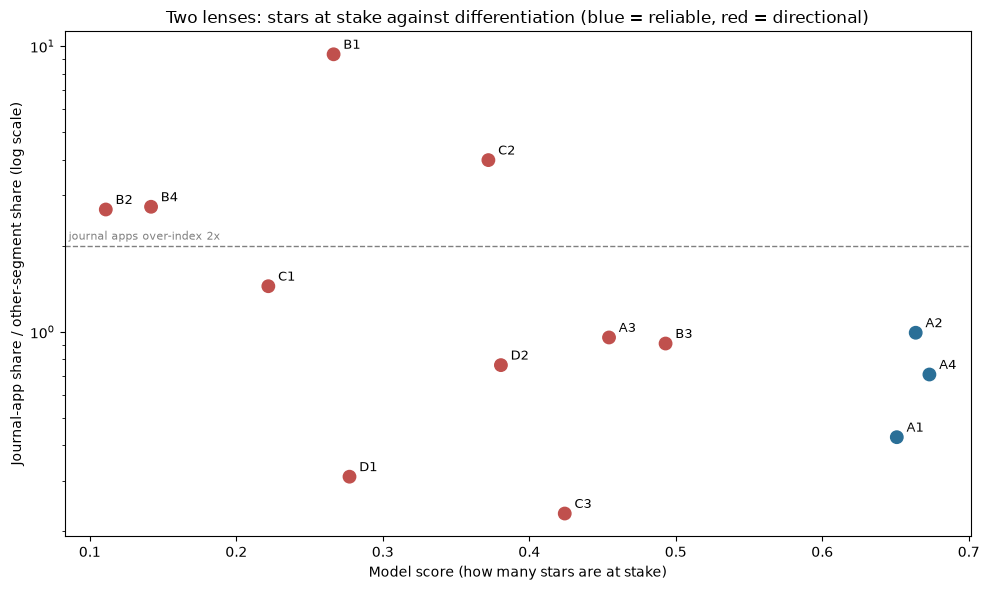

,action_id,action,rank,share_direct,share_others,direct_over_index,avg_rating,tier
0,A4,Release updates carefully (no surprise redesigns),1,5.56,7.85,0.71,2.52,reliable
1,A2,Set a simple transparent pricing model before ...,2,19.46,19.62,0.99,3.35,reliable
2,A1,Keep the app ad-free; never show ads to paying...,3,2.31,5.42,0.43,2.45,reliable
3,B3,Make the account optional (start with no sign-in),4,3.24,3.56,0.91,2.67,directional
4,A3,Never lose a user's entries (device first + ba...,5,9.01,9.44,0.95,2.86,directional
5,C3,Let the user change the due date and state sou...,6,0.46,1.98,0.23,2.65,directional
6,D2,Do not sell or share pregnancy data; say plain...,7,0.39,0.52,0.76,2.54,directional
7,C2,Offer in-app support and easy refunds,8,4.53,1.14,3.99,2.93,directional
8,D1,Do not force AI features,9,0.37,1.19,0.31,3.07,directional
9,B1,Build the core around pregnancy-week journaling,10,28.38,3.03,9.36,4.42,directional


In [47]:
diff = rank_all.copy()  # already carries share_direct, share_others and direct_over_index from the evidence file
diff['over_index_2x'] = diff['direct_over_index'] >= 2

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(diff['score'], diff['direct_over_index'], s=80, c=diff['tier'].map({'reliable': '#2a6f97', 'directional': '#c0504d'}))
for _, r in diff.iterrows():
    ax.annotate(r['action_id'], (r['score'], r['direct_over_index']), textcoords='offset points', xytext=(7, 4), fontsize=9)
ax.set_yscale('log')
ax.axhline(2, color='grey', linestyle='--', linewidth=1)
ax.text(ax.get_xlim()[0], 2.1, ' journal apps over-index 2x', color='grey', fontsize=8)
ax.set_xlabel('Model score (how many stars are at stake)')
ax.set_ylabel('Journal-app share / other-segment share (log scale)')
ax.set_title('Two lenses: stars at stake against differentiation (blue = reliable, red = directional)')
plt.tight_layout()
plt.savefig(FIGS / 'two_lenses.png', dpi=150, bbox_inches='tight')
plt.show()

diff[['action_id', 'action', 'rank', 'share_direct', 'share_others', 'direct_over_index', 'avg_rating', 'tier']].round(2).reset_index(drop=True)

### Takeaways from section 18

**What holds up under any weights**
- **Updates, pricing and ads are the robust top three.** Across 5,000 random weightings, updates (A4) are in the top three in 99% of draws, ads (A1) in 93% and pricing (A2) in 84%. All three rest on reliable rules and 330 to 1,400 mentions.
- **The top five are the same set in every variant I tried:** those three, plus optional account (B3) and data safety (A3). That is true using all reviews, using only the last 24 months, and ignoring effort. This is the most defensible conclusion in the project.
- **Data safety (A3) is less certain.** It ranks fifth by default but is in the top five in only 47% of draws, because its rule is directional, so the model gives it less confidence.

**Where the model and my judgment disagree**
- The model puts the **journaling (B1), inclusivity (B4) and sharing (B2)** actions at 10th, 12th and 13th. They never reach the top three in more than 4% of draws. In my narrative ranking they were 5th, 8th and 6th.
- The reason is what the model measures. It scores how many stars an app loses by failing at a topic. Journaling and sharing are topics reviewers are happy about (4.4 and 4.2 stars), inclusivity is rare (under 2% of reviews), and all three have directional rules, which cost confidence. Sharing is also one of the most expensive to build (a large effort score).
- In the other direction, the model promotes cheap, low-reach fixes: privacy (D2) moves from 13th in my ranking to 7th, and due-date accuracy (C3) from 11th to 6th.

**The second lens: differentiation**
- Journal-style apps talk about memories and journaling **9.4 times** as much as the other segments do (9.9 times in the last 24 months). Customer support is another over-index (4.0 times, 7.9 recently).
- Sharing and inclusivity over-index 2.7 times over all reviews, but only **1.4 times** in the last 24 months, so their case for differentiation is weakening.
- The journaling over-index rests on two apps: Qeepsake (65% of its reviews mention memories) and 280days (18%). It is one real source, not a market.

**What I would conclude**
- **Do first (hygiene):** ads, pricing, updates, optional account and data safety. Both the model and my judgment agree.
- **Treat journaling as a strategic bet,** not an evidence-ranked fix. It is the biggest opening, but the evidence is moderate and needs interviews before it is treated as a requirement.
- **Wait on sharing and inclusivity** until they are validated, since their recent differentiation fades and their rules are weak.

## 19. Plan vs reality: what the evidence says against what Wombloom v1.0 contains

The feature plan for Wombloom came from my own needs as an expectant parent, before this research (section 21). So this section is a **retrospective check of that plan against the evidence**, not a claim that the research shaped the app. It asks what an evidence-led plan would have built, and how Wombloom v1.0 compares. "Shipped", "partial" and "missing" come from the App Store listing, the handoff guide, the dependency list and a search of the source code. Where a feature was not found, that means not found in those files.

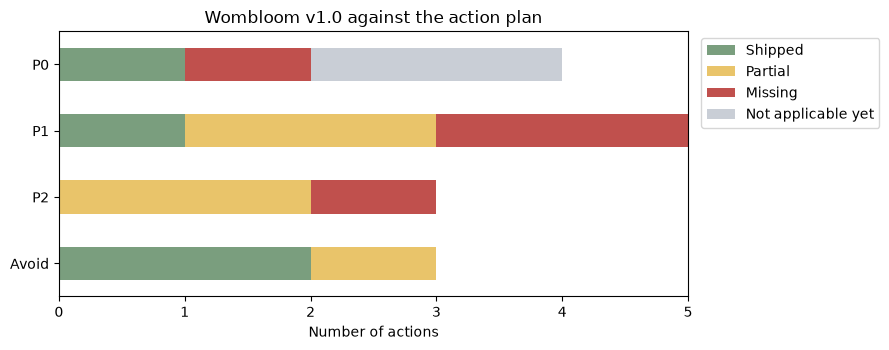

Totals: {'Partial': 5, 'Shipped': 4, 'Missing': 4, 'Not applicable yet': 2}


,action_id,priority,action,strength,v1_status,v1_evidence
0,A1,P0,Keep the app ad-free; never show ads to paying...,Strong,Shipped,Listing says no ads; no advertising SDK in pac...
1,A2,P0,Set a simple transparent pricing model before ...,Strong,Not applicable yet,"App is free with no in-app purchases (listing,..."
2,A3,P0,Never lose a user's entries (device first + ba...,Moderate,Missing,Data lives in the phone's key-value store and ...
3,A4,P0,Release updates carefully (no surprise redesigns),Strong,Not applicable yet,First release (1.0.0); over-the-air updates ar...
4,B1,P1,Build the core around pregnancy-week journaling,Moderate,Partial,"Daily journal page (title, mood, text, photos)..."
5,B2,P1,Let a partner and family follow along (include...,Moderate,Missing,"No accounts and no network access by design, s..."
6,B3,P1,Make the account optional (start with no sign-in),Moderate,Shipped,No account or sign-in exists
7,B4,P1,Be inclusive by default,Exploratory,Partial,Due date is entered at onboarding and wording ...
8,B5,P1,Make keepsakes honest (digital export first),Exploratory,Missing,No export or print feature found
9,C1,P2,Add iOS quick-access features later (widgets a...,Moderate,Missing,"No widget, Watch or Live Activity found; quick..."


In [48]:
status_order = ['Shipped', 'Partial', 'Missing', 'Not applicable yet']
status_colors = {'Shipped': '#7a9e7e', 'Partial': '#e9c46a', 'Missing': '#c0504d', 'Not applicable yet': '#c9ced6'}
by_priority = (pd.crosstab(register['priority'], register['v1_status']).reindex(columns=status_order, fill_value=0)
               .reindex(['P0', 'P1', 'P2', 'Avoid']))

ax = by_priority.plot.barh(stacked=True, figsize=(9, 3.6), color=status_colors)
ax.invert_yaxis()
ax.set_xlabel('Number of actions')
ax.set_ylabel('')
ax.set_title('Wombloom v1.0 against the action plan')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig(FIGS / 'plan_vs_reality.png', dpi=150, bbox_inches='tight')
plt.show()

print('Totals:', register['v1_status'].value_counts().to_dict())
register[['action_id', 'priority', 'action', 'strength', 'v1_status', 'v1_evidence']]

### Features in v1.0 that the research did not cover

Wombloom v1.0 also includes a shopping list with a budget, appointments with calendar sync, growth charts, personalization (paper styles, stickers), ultrasound logging, reminders and a Vietnamese translation. None of these had a theme in the codebook. A quick keyword probe shows how often reviews of the other apps mention them. These are rough keyword counts, not validated rules.

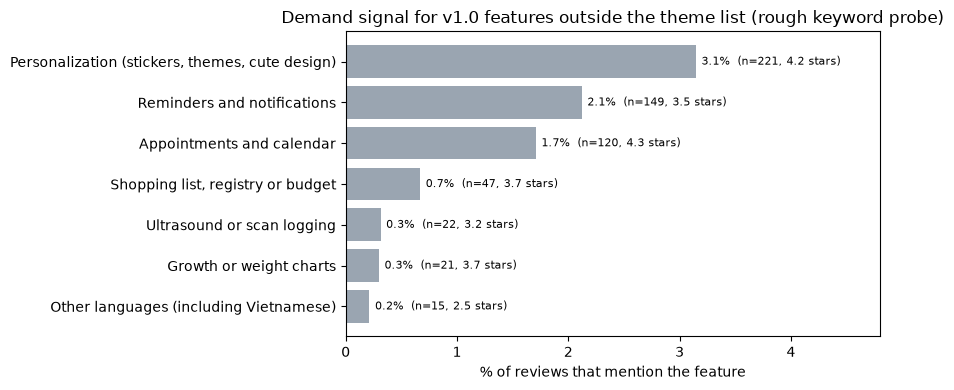

,window,feature,reviews,pct_of_reviews,avg_rating,pct_low
0,last_24m,"Shopping list, registry or budget",23,0.9,4.6,4.3
1,last_24m,"Personalization (stickers, themes, cute design)",90,3.4,4.3,13.3
2,last_24m,Appointments and calendar,34,1.3,4.6,5.9
3,last_24m,Growth or weight charts,10,0.4,4.3,10.0
4,last_24m,Reminders and notifications,56,2.1,3.4,28.6
5,last_24m,Ultrasound or scan logging,6,0.2,3.7,16.7
6,last_24m,Other languages (including Vietnamese),9,0.3,2.1,66.7


In [49]:
probe = pd.read_csv(DASH / 'feature_probe.csv')
probe_all = probe[probe['window'] == 'all'].sort_values('pct_of_reviews')

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(probe_all['feature'], probe_all['pct_of_reviews'], color='#9aa5b1')
for yy, (pct, stars, n) in enumerate(zip(probe_all['pct_of_reviews'], probe_all['avg_rating'], probe_all['reviews'])):
    ax.text(pct + 0.05, yy, f'{pct:.1f}%  (n={n}, {stars:.1f} stars)', va='center', fontsize=8)
ax.set_xlim(0, 4.8)
ax.set_xlabel('% of reviews that mention the feature')
ax.set_ylabel('')
ax.set_title('Demand signal for v1.0 features outside the theme list (rough keyword probe)')
plt.tight_layout()
plt.show()

probe[probe['window'] == 'last_24m'].round(1).reset_index(drop=True)

### Takeaways from section 19

**The scorecard.** Of the 15 actions, v1.0 has **4 shipped, 5 partial, 4 missing and 2 not applicable yet** (pricing and update policy, because the app is a free first release).

**Where the build already matches the evidence**
- Trust and privacy are built in: no ads, no account, no AI and no data collected. Ads, account problems, AI and privacy are among the lowest-rated topics in competitor reviews, so v1.0 avoids several of the biggest complaints by design.

**The gaps that matter**
- **Data safety is the only missing top-priority action.** Entries and photos live only on the phone. I found no backup, export or sync code, and the handoff guide says deleting the app deletes the data. The model also puts this action in its top five. Reviewers of other apps describe exactly this failure ("all of my pictures and journal entries are gone").
- **Partner and family sharing is missing by design,** because there are no accounts and no network. That is a deliberate trade between privacy and sharing. The model ranks it last, and its differentiation is fading, so it is not urgent.
- **Journaling is partial.** v1.0 has daily journal pages with photos, but I found no pregnancy-week prompts. The evidence is double-edged here: Qeepsake users praise prompts, and also complain when they repeat or are not age-appropriate. Prompts should be tested before they are built.

**Features outside the research**
- **Little demand signal in reviews:** shopping list or budget (0.7% of reviews, 47 mentions), growth charts (0.3%) and ultrasound logging (0.3%). Reviews can only mention what apps offer, so an absence is weak evidence about need. Treat these as questions for your own users, not reasons to cut.
- **Positive signal:** personalization (3.1% of reviews, 4.2 stars) and appointments with calendar (1.7%, 4.3 stars).
- **A reliability risk:** reminders and notifications are mentioned in 2.1% of reviews, and 30% of those are 1-2 star, against 17% for all reviews.
- **Vietnamese:** only 15 reviews mention other languages, and the research is in English, so it cannot speak to that market.

**A reading, not a finding:** v1.0 spreads effort across many features (tracking, planning, personalization), while the evidence says apps lose users on reliability, pricing and trust. More features mean more surface for the bugs that reviewers punish most (49% of bug mentions are 1-2 star). I have not tested this. It is a question to ask when planning the next version.

## 20. How I worked with AI

**In one line:** I am the analyst. I own the question, the method, the decisions and the conclusions. AI is an accelerator: it saved me the time of writing and running code and assembling first drafts, which is what let me build a complete research project from scratch on my own. I review what it produces, and where it could not be trusted I tested it.

| | What I owned | What AI accelerated |
|---|---|---|
| **The question** | The product need, from my own pregnancy, and the decisions the research had to support: what to build and in what order | Nothing. This part is not delegated |
| **The method** | I wrote the research plan (`docs/research_plan.md`): scope (iOS, US and Canada, English), competitor selection by a documented and repeatable method, collection rules (polite request rates, no reviewer names or IDs, raw data left untouched), and a review checkpoint at every step | Writing and running the scripts that carry out my plan: API calls, cleaning, loading into a database |
| **The decisions** | Confirmed the 10-app shortlist. Skipped Google Play because iOS is where Wombloom launches. Chose VADER. Required every comparison on two time windows. Approved the theme codebook. Accepted AI-assisted labels with a held-out test and documented that trade-off. Asked for actions and a ranking, not just charts. Chose a free-hosted interactive dashboard | Drafting the tagging rules, tables, charts and dashboard code for me to review |
| **The judgment** | Which findings to trust and which to treat as leads. Keeping the places where the model and my judgment disagree. The product story and the measurement plan (sections 21 and 22) | A first-pass label of 150 reviews, used only to test the rules |

**How I kept the work independent: checks I required.** My plan told the assistant to verify each source before building on it, to stop and report anything blocked instead of working around it, and to pause for my review at set checkpoints. These rules, plus a held-out test, are what caught the problems below.

In [50]:
acc = pd.read_csv(DASH / 'theme_accuracy.csv')
reliable_acc = acc[acc['tier'] == 'reliable']
tp, fp, fn = (acc[c].sum() for c in ['true_pos_test', 'false_pos_test', 'false_neg_test'])
vader_neg = (sample.loc[sample['star_label'] == 'negative', 'sentiment_label'] == 'negative').mean()
tested = acc[acc['hand_labeled_test'] >= 3]

checks = pd.DataFrame([
    ('Hand-labeled validation sample', '150 reviews (100 to tune the rules on, 50 held back for testing)'),
    ('Keyword rules rated reliable', f"{len(reliable_acc)} of {len(acc)} themes; average test F1 {reliable_acc['f1_test'].mean():.2f}"),
    ('All themes pooled, held-out test', f'precision {tp / (tp + fp):.2f}, recall {tp / (tp + fn):.2f}'),
    ('Tuned vs held-out score', f"average F1 {tested['f1_dev'].mean():.2f} on the tuning set vs {tested['f1_test'].mean():.2f} on the test set"),
    ('VADER sentiment against stars', f'{vader_neg:.0%} of 1-2 star reviews were scored negative, so stars decide direction and text explains why'),
    ('Duplicate reviews found in 7,955', '0'),
], columns=['Check', 'Result'])
checks

,Check,Result
0,Hand-labeled validation sample,"150 reviews (100 to tune the rules on, 50 held..."
1,Keyword rules rated reliable,7 of 19 themes; average test F1 0.88
2,"All themes pooled, held-out test","precision 0.76, recall 0.84"
3,Tuned vs held-out score,average F1 0.85 on the tuning set vs 0.76 on t...
4,VADER sentiment against stars,"44% of 1-2 star reviews were scored negative, ..."
5,"Duplicate reviews found in 7,955",0


**What the checks caught**
- **A silent data gap.** The review feed returned an empty page for one app (Pregnancy Tracker App - WTE, US), which the first script recorded as "no reviews". A coverage check at my review checkpoint showed 0 reviews for an app with about 380,000 ratings. The fetcher now re-checks an empty page before treating it as the end.
- **Over-optimistic accuracy.** The rules scored higher on the reviews they were tuned on than on the held-out ones (see the table above). Only the held-out score is reported as the accuracy.
- **A weak tool.** VADER agreed with star ratings overall but missed more than half of the complaints, so it is not used to decide who is unhappy.
- **A codebook that missed things.** Reading reviews showed that feature requests and AI features were missing and that complaint and praise themes should be merged into topics. The changes are documented, and one labeling mistake was corrected.
- **Draft statements that did not match the data.** Several were fixed on review: for example, a claim that baby-tracker data loss was rising (it was not), and calling pricing the "most common complaint" when praise mentions it too.
- **A model that disagreed with my judgment.** The scoring model ranks the journaling idea low. I kept the disagreement visible in section 18 and added a second lens, instead of changing the model until it agreed with me.

**What this does not prove, and what I would do next**
- The 150 validation labels were made by the AI, not by a person, so the accuracy figures show agreement with the AI's own labels. I accepted that trade-off to move faster, and I documented it. The next step is to label about 50 reviews myself, blind, and report how often I agree with the AI.
- The weights and effort scores are assumptions. The stress test shows which conclusions survive them.
- Everything can be re-run: the scripts in the README produce every number in this notebook.

## 21. How Wombloom was built: from a personal problem to a testable product

*Written from my own account. The product facts come from the project files.*

**1. I started with the problem, not the app.**
I was pregnant and wanted every moment of the journey in one place. I had many photos in my library, but unorganized, and a lot to keep track of at once: checkup appointments, insurance checks, a shopping list. They were all in different places. Before designing any screen, I listed everything I needed, then planned the app around that list.

My needs fell into three groups, which is how I thought about the app's main areas:
- **Remember:** photos and a journal of the pregnancy.
- **Plan:** checkups, appointments and insurance checks.
- **Prepare:** a shopping list and a budget.

**2. I treated my own experience as a hypothesis, not as evidence.**
I was my own first user. That is a useful source of ideas and a weak source of proof, because one person is not a market. It is also biased: I knew what I wanted before I knew what other parents wanted. That is why I did not stop at my own list, and why market research was the next step.

**3. I turned the problem into a specification an AI could build.**
I am not a software engineer, so my job was to make the features, the roadmap and the flow of the app detailed enough for an AI to build correctly. The technical part was the easy part, because the assistant handles it. The hard part was the thinking: deciding the flow of the app, and deciding **how many features is reasonable**. Every feature added makes the app harder to use and to keep working, so each one had to justify its place. That is analyst work: prioritization, scope and trade-offs.

**4. I tested my plan against the market.**
With the plan in place, I asked AI to carry out market research using my own method, and I used the results to prioritize features (sections 1 to 19). Here is how my plan did against the evidence.
- **It held up on trust.** No ads, no account and no data collected avoid several of the lowest-rated topics in competitors' reviews.
- **It has a gap the evidence points to:** backup and export (section 19). Entries and photos live only on the phone, and losing them is the failure reviewers punish most.
- **Some of my own needs showed little demand in competitors' reviews:** the shopping list and budget (0.7% of reviews mention them). That does not prove the need is not real. Reviews can only mention what apps offer, so an absence is weak evidence. It is a question for my own users, not a reason to cut the feature.
- **A risk I would test:** more features mean more places for the bugs and reminder failures that reviewers punish. I have not tested this.

**5. What I would reconsider for the next version:** add backup and export first, decide the pricing model before charging for anything, test pregnancy-week prompts before building them, and ask my users which features they actually use each week.

**6. It is not measured yet.** I have not promoted the app, and I do not have enough users. So rather than claim results, I designed the measurement plan first (section 22).

**What the project files show**
- **The product:** a private pregnancy-to-first-years journal for iPhone, in English and Vietnamese: daily journal pages with photos, a milestone timeline, feed, sleep and diaper logging, growth charts, appointments with calendar sync, a shopping list with a budget, and personalization (paper styles, stickers).
- **How it is built:** Expo (React Native) with TypeScript, about 5,300 lines across 21 source files. All data stays on the phone, with no account, no network access, no analytics, no ads and no in-app purchases.
- **AI-assisted development:** the project contains Claude Code configuration and an `AGENTS.md` file with instructions for AI coding agents.
- **Release path:** builds and App Store submission run through Expo's cloud build service. A handoff guide, App Store listing copy, a privacy policy and an age-rating questionnaire are drafted. The privacy policy URL, support URL and publisher details are placeholders in those documents.
- **Promotion:** a 14-day social pack (21 October to 3 November) with 14 images and 4 short videos in each of English and Vietnamese, plus image carousels in both languages.

## 22. Measurement plan: how I will know whether Wombloom works

*Wombloom has not been promoted yet and has too few users to measure, so nothing in this section is a result. It is the plan I would commit to before launch, so that the thresholds cannot be chosen after the numbers are in.*

**Principles**
1. **Every metric is tied to a decision.** If no decision would change, I do not track it.
2. **Respect the privacy promise.** Wombloom's store label is "Data Not Collected". Adding analytics would change it, so I measure in tiers and only move up when a specific question needs it.
3. **Small numbers need honest uncertainty.** I report ranges, not only percentages.
4. **Thresholds are written down before I look at results.**

### Three tiers of measurement

| Tier | Source | What it can answer | Privacy effect |
|---|---|---|---|
| **1** | App Store Connect analytics (impressions, product page views, conversion, downloads, sessions, retention, crashes, ratings by version), with a separate campaign link per promotion source and per language | Is the promotion reaching people and converting them? Do they come back? Is the build stable? | None. Apple provides it and there is no tracking code in the app. Usage and retention figures cover only users who chose to share data with developers, so they describe a sample |
| **2** | A short survey, 5 to 10 interviews, TestFlight feedback, and my own App Store reviews analyzed with this project's theme rules | Why do people stay or leave? Which features do they really use? | None. People choose to respond |
| **3** | Opt-in anonymous usage counts inside the app, such as entries written per week | Activation and feature use that tiers 1 and 2 cannot see | Changes the privacy label. Only if a specific question justifies it |

What each App Store Connect report offers should be confirmed in the account before launch.

### The metric tree

| Stage | Metric | Source | Decision it informs |
|---|---|---|---|
| Acquire | Impressions, product page views and downloads, with conversion at each step, by source and by language | Tier 1 | Which post types and which language to repeat |
| Activate | Share of new users who write a first entry in the first week | Tier 2 survey now (self-reported), tier 3 later if needed | Does onboarding work? |
| Retain | Day-1, day-7 and day-28 retention; sessions per active device | Tier 1 | Does a journal become a habit? |
| Value | Which features people use each week, and which they would miss | Tier 2 | Keep, change or cut features (shopping list, growth charts, personalization) |
| Satisfaction | Rating by version; share of 1-2 star reviews; theme rates in my own reviews | Tier 1 and 2 | How Wombloom compares with the competitor baseline below |
| Quality | Crash-free sessions; reminders that fire; reports of lost data | Tier 1 and 2 | The data-safety risk (action A3) |
| Advocacy | "How likely are you to recommend Wombloom?" (0 to 10) and one open question | Tier 2 | Is there enough satisfaction to grow by word of mouth? |

### Tying the metrics back to the research
Each action from section 17 has a way to measure it:

In [51]:
register[['action_id', 'priority', 'action', 'measurement_idea']].rename(columns={'measurement_idea': 'How I would measure it'})

,action_id,priority,action,How I would measure it
0,A1,P0,Keep the app ad-free; never show ads to paying...,Share of own App Store reviews that mention ad...
1,A2,P0,Set a simple transparent pricing model before ...,Willingness-to-pay survey; share of own review...
2,A3,P0,Never lose a user's entries (device first + ba...,Crash-free sessions and retention (App Store C...
3,A4,P0,Release updates carefully (no surprise redesigns),Rating by version (App Store Connect); own rev...
4,B1,P1,Build the core around pregnancy-week journaling,Day-7 and day-30 retention (App Store Connect)...
5,B2,P1,Let a partner and family follow along (include...,Survey or fake-door test of demand before buil...
6,B3,P1,Make the account optional (start with no sign-in),Own reviews that mention login or sign-in (tar...
7,B4,P1,Be inclusive by default,"Interviews with LGBTQ+, IVF and surrogacy fami..."
8,B5,P1,Make keepsakes honest (digital export first),Interviews; not scored (no clean topic)
9,C1,P2,Add iOS quick-access features later (widgets a...,Requests in own reviews


### A competitor baseline to compare against
Once Wombloom has its own reviews, I can run them through the same theme rules and compare. These are the competitors' numbers to compare against. The last column is left blank on purpose.

In [52]:
baseline_topics = pd.read_csv(DASH / 'theme_impact.csv')
baseline_topics = baseline_topics[baseline_topics['window'] == 'all']
bench = baseline_topics[baseline_topics['theme'].isin(['ADS', 'PRICE', 'UPDATE', 'BUGS', 'DATA', 'ACCOUNT', 'PRIVACY', 'AI'])]
bench = bench[['label', 'tier', 'pct_of_reviews', 'avg_rating', 'pct_low']].rename(columns={
    'label': 'Topic', 'tier': 'Rule', 'pct_of_reviews': 'Competitors: % of reviews', 'avg_rating': 'Competitors: avg stars', 'pct_low': 'Competitors: % 1-2 star'})
bench['Wombloom (fill in once reviews exist)'] = ''
bench.round(1).reset_index(drop=True)

,Topic,Rule,Competitors: % of reviews,Competitors: avg stars,Competitors: % 1-2 star,Wombloom (fill in once reviews exist)
0,Ads,reliable,4.8,2.4,59.0,
1,Pricing and subscription,reliable,20.0,3.4,36.5,
2,Updates and redesigns,reliable,7.2,2.5,56.5,
3,"Bugs, crashes and slowness",reliable,6.2,2.6,49.3,
4,Data loss and sync,directional,3.6,3.2,38.4,
5,Account and login,directional,3.6,2.7,53.2,
6,Privacy and data use,directional,0.5,2.5,56.8,
7,AI features,directional,1.0,3.1,41.7,


### Evaluating the promotion as an experiment
The 14-day social pack (28 posts: 14 days in English and in Vietnamese) can answer a few questions. The log template is `data/measurement/promo_post_log.csv`: one row per post, with the metrics left blank to fill in.

| Hypothesis | Measured by | Decision |
|---|---|---|
| Question and prompt posts earn more saves and shares than tip posts | Saves and shares per post, by post type | Which post types to repeat |
| Vietnamese and English posts differ in link clicks | Link clicks and product page views by language | Which language and market to prioritize |
| Posts with a video reach more people than images alone (8 of the 28 have one) | Reach by whether the post has a video | Whether video is worth the effort |

**How I will read it honestly.** There are only 14 posts per language, they were not randomized, and day of the week and the platform's own ranking will confound the comparison. So I will compare medians and ranges, and call differences suggestive, not proven.

### How much can a small sample tell me?
The margin of error for a share (such as "30% use the shopping list weekly") shrinks slowly. The worst case is a true share of 50%:

In [53]:
n = np.array([30, 50, 100, 200, 400])
margin = 1.96 * np.sqrt(0.25 / n) * 100  # worst-case 95% margin of error, in percentage points
pd.DataFrame({'survey or cohort size (n)': n, '95% margin of error (+/- points)': margin.round(1)})

,survey or cohort size (n),95% margin of error (+/- points)
0,30,17.9
1,50,13.9
2,100,9.8
3,200,6.9
4,400,4.9


So a survey of 50 people can separate "most people use it" from "few people use it", but not 30% from 40%. That is why decisions will rest on clear gaps and on the interviews, not on small differences.

### Before launch
- Create one campaign link per promotion source, and per language, English and Vietnamese.
- Set up the survey and the feedback channel, and decide the thresholds in writing.
- Fill in `data/measurement/promo_post_log.csv` after each post.
- Plan to run Wombloom's own reviews through the theme rules once there are enough of them.

## 23. The dashboard

The dashboard turns this notebook into something a reader can explore. It is a Streamlit app in `dashboard/`. It reads only aggregated data files and the short list of public quotes, in `data/aggregates/` and `data/registers/`. No review table and no reviewer data are included.

| Tab | What a reader can do |
|---|---|
| Summary | See the headline findings and the caveats |
| Feature gap matrix | Filter by time window, segment and rule reliability |
| Prioritization | Change the weights and the effort estimates, and watch the ranking and its stability change |
| Evidence | Pick an action and read its numbers and quotes |
| Plan vs reality | Filter the 15 actions by what v1.0 shipped |
| Method | See the rule accuracy, the limitations and how AI was used |

**Run it locally:** `streamlit run dashboard/app.py` from the project folder.

**Publish it free:** push the project to a public GitHub repository, then deploy `dashboard/app.py` on Streamlit Community Cloud. The steps are in `dashboard/README.md`.